# Dota 2 Games Results — a small experimental study
## Research question
**RQ:** How well can the ten hero picks and the match settings, known *before* a match starts, predict whether **Team 1** wins?

**Task:** binary classification, `y = 1` if Team 1 wins, `0` if Team 2 wins.
**Data:** UCI *Dota2 Games Results* (Tridgell, 2016), CC BY 4.0, doi:10.24432/C5W593 — 92,650 training and 10,294 test matches, all played within about two hours on 13 August 2016.

**How to run:** start Jupyter from the `notebooks/` folder (data in `../data/`), then *Kernel → Restart & Run All*. Same results on Windows and Linux (fixed seed 42). Runtime about 5–10 minutes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)

print("Imports successful.")

Imports successful.


In [2]:
files = sorted(Path("../data").rglob("*.csv"))

for file in files:
    print(file)

..\data\dota2Test.csv
..\data\dota2Train.csv
..\data\SkillCraft1_Dataset.csv


In [3]:
raw_train = pd.read_csv("../data/dota2Train.csv", header=None)
raw_test = pd.read_csv("../data/dota2Test.csv", header=None)

print("Train shape:", raw_train.shape)
print("Test shape:", raw_test.shape)
print("Total matches:", len(raw_train) + len(raw_test))

raw_train.iloc[:5, :12]

Train shape: (92650, 117)
Test shape: (10294, 117)
Total matches: 102944


,0,1,2,3,4,5,6,7,8,9,10,11
0,-1,223,2,2,0,0,0,0,0,0,0,0
1,1,152,2,2,0,0,0,1,0,-1,0,0
2,1,131,2,2,0,0,0,1,0,-1,0,0
3,1,154,2,2,0,0,0,0,0,0,-1,0
4,-1,171,2,3,0,0,0,0,0,-1,0,0


In [4]:
columns = (
    ["win", "clusterid", "gamemode", "gametype"]
    + [f"hero_{i}" for i in range(1, 114)]
)

print("Number of column names:", len(columns))

train = raw_train.copy()
test = raw_test.copy()

train.columns = columns
test.columns = columns

train.iloc[:5, :12]

Number of column names: 117


,win,clusterid,gamemode,gametype,hero_1,hero_2,hero_3,hero_4,hero_5,hero_6,hero_7,hero_8
0,-1,223,2,2,0,0,0,0,0,0,0,0
1,1,152,2,2,0,0,0,1,0,-1,0,0
2,1,131,2,2,0,0,0,1,0,-1,0,0
3,1,154,2,2,0,0,0,0,0,0,-1,0
4,-1,171,2,3,0,0,0,0,0,-1,0,0


In [5]:
print("WIN VALUES:")
print(train["win"].value_counts().sort_index())

print("\nGAME MODE VALUES:")
print(train["gamemode"].value_counts().sort_index())

print("\nGAME TYPE VALUES:")
print(train["gametype"].value_counts().sort_index())

print("\nNUMBER OF CLUSTERS:")
print(train["clusterid"].nunique())

print("\nMISSING VALUES:")
print(train.isna().sum().sum())

WIN VALUES:
win
-1    43868
 1    48782
Name: count, dtype: int64

GAME MODE VALUES:
gamemode
1     1229
2    71897
3      386
4      208
5       12
6      498
7       81
8     8306
9    10033
Name: count, dtype: int64

GAME TYPE VALUES:
gametype
1       15
2    56988
3    35647
Name: count, dtype: int64

NUMBER OF CLUSTERS:
47

MISSING VALUES:
0


In [6]:
hero_cols = [f"hero_{i}" for i in range(1, 114)]

# What values occur in the hero columns?
hero_values = np.unique(train[hero_cols].values)

print("Unique hero values:")
print(hero_values)

# How many heroes are selected in each match?
selected_per_match = (train[hero_cols] != 0).sum(axis=1)

print("\nNumber of selected heroes per match:")
print(selected_per_match.value_counts().sort_index())

# How many heroes belong to each team?
team1_per_match = (train[hero_cols] == 1).sum(axis=1)
team2_per_match = (train[hero_cols] == -1).sum(axis=1)

print("\nTeam 1 hero counts:")
print(team1_per_match.value_counts().sort_index())

print("\nTeam 2 hero counts:")
print(team2_per_match.value_counts().sort_index())

Unique hero values:
[-1  0  1]

Number of selected heroes per match:
10    92650
Name: count, dtype: int64



Team 1 hero counts:
5    92650
Name: count, dtype: int64

Team 2 hero counts:
5    92650
Name: count, dtype: int64


In [7]:
total_hero_cells = train[hero_cols].size
zero_hero_cells = (train[hero_cols] == 0).sum().sum()

sparsity = zero_hero_cells / total_hero_cells * 100

print("Total hero cells:", total_hero_cells)
print("Zero-valued hero cells:", zero_hero_cells)
print(f"Sparsity: {sparsity:.2f}%")

Total hero cells: 10469450
Zero-valued hero cells: 9542950
Sparsity: 91.15%


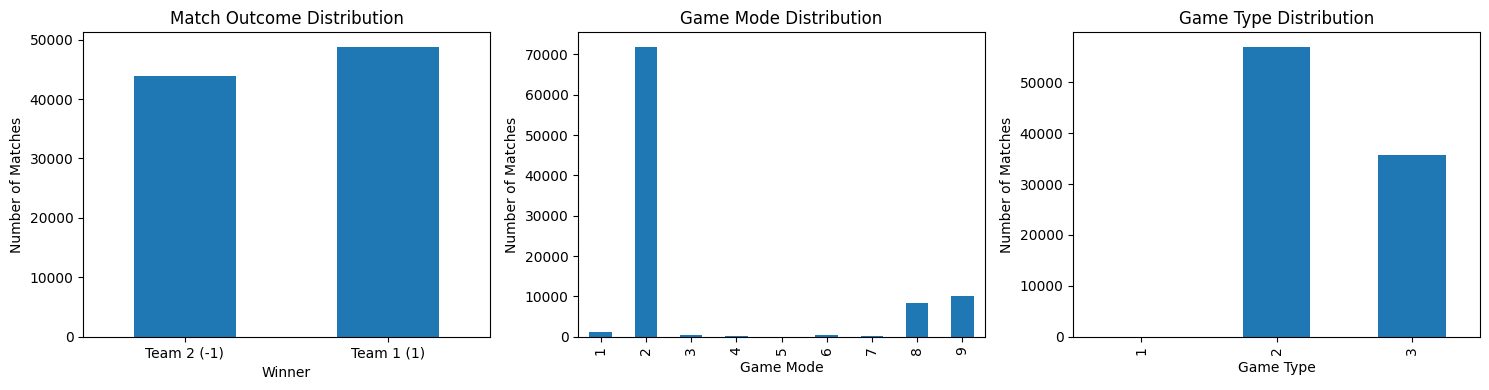

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Win distribution
train["win"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Match Outcome Distribution")
axes[0].set_xlabel("Winner")
axes[0].set_ylabel("Number of Matches")
axes[0].set_xticklabels(["Team 2 (-1)", "Team 1 (1)"], rotation=0)

# 2. Game mode distribution
train["gamemode"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Game Mode Distribution")
axes[1].set_xlabel("Game Mode")
axes[1].set_ylabel("Number of Matches")

# 3. Game type distribution
train["gametype"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[2]
)
axes[2].set_title("Game Type Distribution")
axes[2].set_xlabel("Game Type")
axes[2].set_ylabel("Number of Matches")

plt.tight_layout()
plt.savefig("../figures/dota2_match_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
hero_usage = (train[hero_cols] != 0).sum().sort_values(ascending=False)

print("15 most frequently selected heroes:")
print(hero_usage.head(15))

15 most frequently selected heroes:
hero_9      32048
hero_44     29802
hero_14     28285
hero_104    26521
hero_8      23327
hero_93     23125
hero_6      21700
hero_74     21262
hero_2      20264
hero_32     19670
hero_35     17276
hero_98     17155
hero_18     17029
hero_41     16746
hero_1      14973
dtype: int64


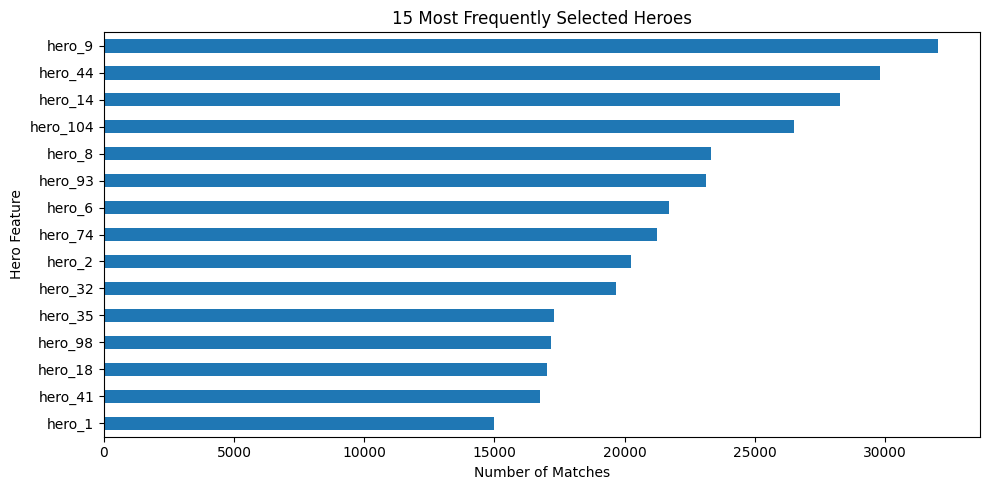

In [10]:
top15 = hero_usage.head(15)

plt.figure(figsize=(10, 5))
top15.sort_values().plot(kind="barh")

plt.title("15 Most Frequently Selected Heroes")
plt.xlabel("Number of Matches")
plt.ylabel("Hero Feature")

plt.tight_layout()
plt.savefig("../figures/dota2_top15_hero_usage.png", dpi=150, bbox_inches="tight")
plt.show()

## 1. Setup
This cell adds the libraries and the shared settings.

In [11]:
import os, platform, time, warnings
from pathlib import Path

import matplotlib
import scipy
import sklearn
from joblib import Parallel, delayed
from scipy import stats

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_squared_error,
                             precision_score, recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.naive_bayes import BernoulliNB, CategoricalNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                          # one seed everywhere -> identical numbers on every machine
FIG_DIR = Path("../figures")       # relative paths: work on Windows and Linux when run from notebooks/
TABLE_DIR = Path("../results")     # every result table is also saved as CSV here (for the report)
FIG_DIR.mkdir(exist_ok=True); TABLE_DIR.mkdir(exist_ok=True)
N_JOBS = max(1, min(4, (os.cpu_count() or 2) - 1))   # CPU cores for parallel CV (max 4 keeps RAM use safe; set 1 if memory runs out)
HERO_COLS = hero_cols              # hero_1 ... hero_113, created by the original cells

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("machine:", platform.platform())
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

machine: Windows-10-10.0.26300-SP0
python 3.10.0 | numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9 | scipy 1.15.3 | scikit-learn 1.7.2


## 2. Data quality checks and feature analysis
### 2.1 Data quality checks
None of these checks use the official test labels to make a decision, so the test set stays unseen.

In [12]:
# (a) Heroes that are never picked in training carry no information -> they will be dropped.
never_train = [h for h in HERO_COLS if (train[h] != 0).sum() == 0]
print("Heroes never picked in train:", never_train)

# (b) Duplicates or train/test overlap would inflate scores.
print("Duplicate rows - train:", train.duplicated().sum(), "| test:", test.duplicated().sum())
print("Rows in both train and test:", len(pd.merge(train.drop_duplicates(), test.drop_duplicates(), how="inner")))

# (c) Every category in the test file must exist in training (needed for one-hot encoding).
print("Unseen in train -> clusterid:", set(test.clusterid) - set(train.clusterid),
      "| gamemode:", set(test.gamemode) - set(train.gamemode), "| gametype:", set(test.gametype) - set(train.gametype))

# (d) Class balance: 'always predict Team 1' is the floor every model must beat.
print(f"Team 1 win rate - train: {(train.win == 1).mean():.4f}")

Heroes never picked in train: ['hero_24', 'hero_108']
Duplicate rows - train: 0 | test: 0


Rows in both train and test: 0
Unseen in train -> clusterid: set() | gamemode: set() | gametype: set()
Team 1 win rate - train: 0.5265


**Preprocessing decisions that follow**
* **Target:** `y = 1` if Team 1 wins, else `0`. The two classes are close to balanced (about 53 / 47), so plain stratified splits are enough; no re-sampling is needed. Stratification keeps the 53 / 47 ratio in every fold.
* **Drop never-picked heroes** (`hero_24`, `hero_108`): constant zero columns → 111 hero features.
* **No scaling / normalisation:** heroes are already on a common −1 / 0 / +1 scale and the other inputs are categories, so there is nothing to rescale (normalisation is only needed for numeric attributes on different scales).
* **`gamemode`, `gametype`, `clusterid` are codes, not quantities** → one-hot encoding (one yes/no column per value). Rare game modes (fewer than 1,000 training matches: 3, 4, 5, 6, 7) are pooled into one `other` level.
* **Hero representation:** *signed* (one column per hero, +1 / −1 / 0) or *team split* (two yes/no columns per hero: "on Team 1", "on Team 2"). Naive Bayes needs the team split (Section 7).
* **No leakage:** every step that learns from data (encoder, feature selector) sits inside a scikit-learn `Pipeline`, so in cross-validation it is refitted on the training folds only.

In [13]:
USED_HEROES = [h for h in HERO_COLS if h not in never_train]
GAMEMODE_KEEP = [1, 2, 8, 9]                 # modes with >= 1,000 training matches; the rest -> 0 ('other')
FEATURE_COLS = USED_HEROES + ["gamemode_grp", "gametype", "clusterid"]


def build_features(df):
    """Feature table: 111 signed hero columns + grouped game mode + game type + cluster id (no target)."""
    X = df[USED_HEROES + ["gametype", "clusterid"]].copy()
    X["gamemode_grp"] = np.where(df["gamemode"].isin(GAMEMODE_KEEP), df["gamemode"], 0)
    return X[FEATURE_COLS]


# Training data = everything we may learn from. The official test set is put aside until Section 9.
X_train, y_train = build_features(train), (train["win"] == 1).astype(int)
X_test, y_test = build_features(test), (test["win"] == 1).astype(int)
print("training:", X_train.shape, "| official test (locked until Section 9):", X_test.shape)

training: (92650, 114) | official test (locked until Section 9): (10294, 114)


### 2.2 Which inputs are associated with winning? (training data only)
**Heroes.** For each hero we compute (i) how often it is picked, (ii) its win-rate (share of its matches won by its own team) and (iii) its correlation with the target. Because a hero column is +1 for Team 1 and −1 for Team 2, a **positive correlation** means "this hero tends to be on the winning side" and a **negative** one the opposite, so this one number covers both classes.

In [14]:
H = X_train[USED_HEROES].to_numpy(); yv = y_train.to_numpy()
picks = (H != 0).sum(axis=0)
wins = ((H > 0) * yv[:, None] + (H < 0) * (1 - yv[:, None])).sum(axis=0)       # matches won by the hero's team
hero_stats = pd.DataFrame({"hero": USED_HEROES, "picks": picks, "win_rate": wins / picks})
hero_stats["corr_with_win"] = [np.corrcoef(H[:, j], yv)[0, 1] for j in range(H.shape[1])]   # point-biserial r
hero_stats["z"] = (hero_stats.win_rate - 0.5) / np.sqrt(0.25 / hero_stats.picks)           # distance from 50% in standard errors
hero_stats = hero_stats.sort_values("corr_with_win", key=abs, ascending=False).reset_index(drop=True)
outside = (hero_stats.z.abs() > 1.96).sum()
print(f"Hero win-rates range from {hero_stats.win_rate.min():.3f} to {hero_stats.win_rate.max():.3f}")
print(f"Heroes whose win-rate differs from 50% beyond chance (|z| > 1.96): {outside} of {len(hero_stats)} "
      f"(about {0.05 * len(hero_stats):.0f} expected if heroes had no effect)")
print(f"Largest |correlation| of a single hero with the outcome: {hero_stats.corr_with_win.abs().max():.3f}")
hero_stats.round(4).to_csv(TABLE_DIR / "dota2_hero_association.csv", index=False)
hero_stats.head(10).round(4)

Hero win-rates range from 0.356 to 0.609


Heroes whose win-rate differs from 50% beyond chance (|z| > 1.96): 79 of 111 (about 6 expected if heroes had no effect)
Largest |correlation| of a single hero with the outcome: 0.065


,hero,picks,win_rate,corr_with_win,z
0,hero_57,8320,0.6085,0.0649,19.7996
1,hero_9,32048,0.5532,0.0621,19.0482
2,hero_21,14473,0.4358,-0.0508,-15.4359
3,hero_53,7269,0.4164,-0.0486,-14.2508
4,hero_106,7472,0.4217,-0.0447,-13.5353
5,hero_36,10729,0.5645,0.0438,13.3519
6,hero_103,5959,0.5857,0.0437,13.2263
7,hero_39,6538,0.4195,-0.0427,-13.0105
8,hero_32,19670,0.5455,0.0423,12.7629
9,hero_74,21262,0.4588,-0.0397,-12.0152


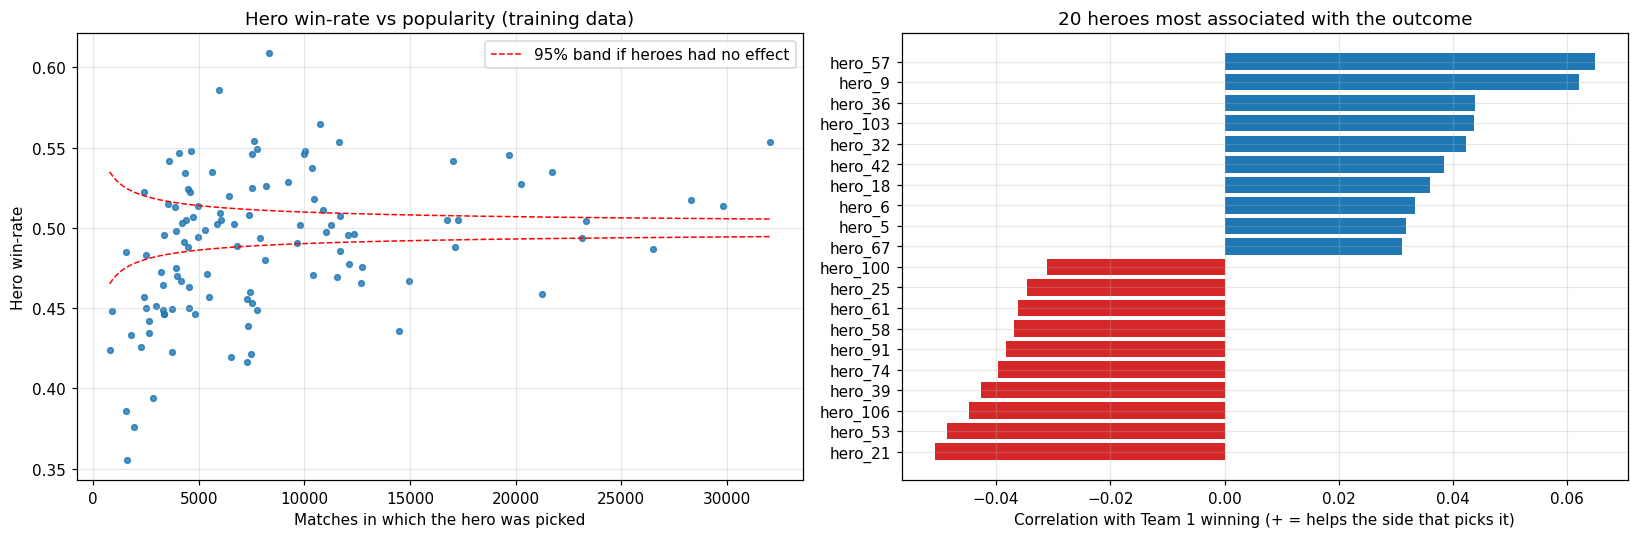

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Left: win-rate vs popularity with the 95% 'no hero effect' funnel.
ax = axes[0]
ax.scatter(hero_stats.picks, hero_stats.win_rate, s=14, alpha=0.8)
g = np.linspace(hero_stats.picks.min(), hero_stats.picks.max(), 200)
ax.plot(g, 0.5 + 1.96 * np.sqrt(0.25 / g), "r--", lw=1, label="95% band if heroes had no effect")
ax.plot(g, 0.5 - 1.96 * np.sqrt(0.25 / g), "r--", lw=1)
ax.set_xlabel("Matches in which the hero was picked"); ax.set_ylabel("Hero win-rate")
ax.set_title("Hero win-rate vs popularity (training data)"); ax.legend()
# Right: the 20 heroes most correlated with the outcome.
top20 = hero_stats.head(20).sort_values("corr_with_win")
axes[1].barh(top20.hero, top20.corr_with_win, color=np.where(top20.corr_with_win > 0, "tab:blue", "tab:red"))
axes[1].set_xlabel("Correlation with Team 1 winning (+ = helps the side that picks it)")
axes[1].set_title("20 heroes most associated with the outcome")
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_hero_association.png", dpi=150, bbox_inches="tight"); plt.show()

**Match settings.** A chi-square test of independence checks whether the Team 1 win-rate differs between game modes, game types or clusters more than chance would explain. A small p-value means "associated"; Cramér's V (0 = none, 1 = perfect) tells how *strongly*.

In [16]:
def chi2_assoc(col):
    tab = pd.crosstab(X_train[col], y_train)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return dict(feature=col, levels=tab.shape[0], chi2=chi2, dof=dof, p_value=p, cramers_v=v)


setting_assoc = pd.DataFrame([chi2_assoc(c) for c in ["gamemode_grp", "gametype", "clusterid"]])
setting_assoc.to_csv(TABLE_DIR / "dota2_setting_association.csv", index=False)
setting_assoc.round(4)

,feature,levels,chi2,dof,p_value,cramers_v
0,gamemode_grp,5,17.3120,4,0.0017,0.0137
1,gametype,3,0.7135,2,0.6999,0.0028
2,clusterid,47,51.1006,46,0.2802,0.0235


Overall Team 1 win rate 0.5265; binomial test vs 0.5: p = 1.2e-58
             matches  team1_win_rate    ci95
mode                                        
other (3-7)     1185          0.5696  0.0282
mode 1          1229          0.5598  0.0278
mode 2         71897          0.5252  0.0037
mode 8          8306          0.5332  0.0107
mode 9         10033          0.5216  0.0098


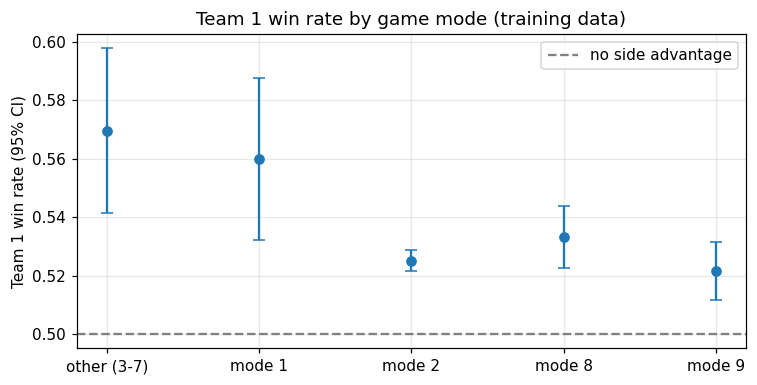

In [17]:
by_mode = (pd.DataFrame({"mode": X_train["gamemode_grp"], "y": y_train})
           .groupby("mode")["y"].agg(["size", "mean"]).rename(columns={"size": "matches", "mean": "team1_win_rate"}))
by_mode["ci95"] = 1.96 * np.sqrt(by_mode.team1_win_rate * (1 - by_mode.team1_win_rate) / by_mode.matches)
by_mode.index = by_mode.index.map(lambda m: "other (3-7)" if m == 0 else f"mode {m}")
bt = stats.binomtest(int(y_train.sum()), len(y_train), 0.5)
print(f"Overall Team 1 win rate {y_train.mean():.4f}; binomial test vs 0.5: p = {bt.pvalue:.1e}")
print(by_mode.round(4))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(range(len(by_mode)), by_mode.team1_win_rate, yerr=by_mode.ci95, fmt="o", capsize=4)
ax.axhline(0.5, color="grey", ls="--", label="no side advantage")
ax.set_xticks(range(len(by_mode))); ax.set_xticklabels(by_mode.index)
ax.set_ylabel("Team 1 win rate (95% CI)"); ax.set_title("Team 1 win rate by game mode (training data)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_team1_winrate_by_mode.png", dpi=150, bbox_inches="tight"); plt.show()

Heroes are associated with winning: 79 of the 111 heroes have win-rates outside the 95% band around 50%. However, the strongest individual correlation is only 0.065, so a single hero provides very little predictive information. clusterid has no statistically significant association with winning (p = 0.2802), and its Cramér’s V of 0.0235 shows a very weak relationship. This suggests that hero picks contain some useful information, but the draft alone cannot make the outcome certain.
&nbsp;

## 3. Experimental protocol
* **Official test set (10,294 matches): used once, in Section 9**, after every choice has been fixed. It is never used for feature selection, tuning or model choice.
* **Everything else uses 10-fold stratified cross-validation on the 92,650 training matches**: the training data is cut into 10 equal parts with the same 53 / 47 class ratio; each part is used once for scoring while the model is trained on the other nine. We report the **mean and standard deviation** over the 10 folds.
* For every cross-validated model we also record **training accuracy** (accuracy on the data it was trained on). A large gap between training and CV accuracy = **overfitting**.
* **Metrics:** accuracy, TP, FP, TN, FN, sensitivity (= recall = TP rate), specificity (= TN rate), FP rate, precision, F1 and ROC-AUC. The positive class is "Team 1 wins". Confusion counts come from the pooled out-of-fold predictions (each training match predicted once, by the model that did not see it).
* **Why several metrics:** accuracy is easy to read but must be compared with the 53 % "always Team 1" floor; ROC-AUC does not depend on the 0.5 cut-off and is 0.5 for guessing; precision / recall / specificity show *which* side the errors fall on.

In [18]:
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)   # the same 10 folds for every experiment
CV_RESULTS = []                                                       # one row per cross-validated configuration


def eval_metrics(y_true, y_pred, proba=None):
    """All evaluation metrics for a binary problem (positive class = Team 1 wins)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = dict(accuracy=(tp + tn) / (tp + tn + fp + fn), TP=tp, FP=fp, TN=tn, FN=fn,
               sensitivity=tp / (tp + fn), specificity=tn / (tn + fp), FP_rate=fp / (fp + tn),
               precision=tp / (tp + fp) if tp + fp else 0.0, recall=tp / (tp + fn),
               F1=f1_score(y_true, y_pred, zero_division=0))
    out["ROC_AUC"] = roc_auc_score(y_true, proba) if proba is not None else np.nan
    return out


def _one_fold(model, X, y, tr, va):
    warnings.filterwarnings("ignore")      # e.g. 'did not converge' when we deliberately allow very few iterations
    m = clone(model)
    t0 = time.perf_counter(); m.fit(X.iloc[tr], y.iloc[tr]); fit_s = time.perf_counter() - t0
    p = m.predict_proba(X.iloc[va])[:, 1]
    train_acc = accuracy_score(y.iloc[tr], m.predict(X.iloc[tr]))
    return va, p, train_acc, fit_s


def cv_evaluate(model, name, experiment, X=None, y=None, settings=""):
    """10-fold stratified CV on the TRAINING data only. Returns (and stores) one row of metrics."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    folds = Parallel(n_jobs=N_JOBS)(delayed(_one_fold)(model, X, y, tr, va) for tr, va in CV10.split(X, y))
    oof = np.zeros(len(y)); fold_acc, fold_auc, train_acc, fit_s = [], [], [], []
    for va, p, tr_acc, secs in folds:
        oof[va] = p
        fold_acc.append(accuracy_score(y.iloc[va], p >= 0.5)); fold_auc.append(roc_auc_score(y.iloc[va], p))
        train_acc.append(tr_acc); fit_s.append(secs)
    row = dict(experiment=experiment, model=name, settings=settings,
               train_acc=np.mean(train_acc), cv_acc=np.mean(fold_acc), cv_acc_sd=np.std(fold_acc),
               cv_auc=np.mean(fold_auc), cv_auc_sd=np.std(fold_auc),
               **eval_metrics(y, (oof >= 0.5).astype(int), oof), fit_s=np.mean(fit_s))
    row["overfit_gap"] = row["train_acc"] - row["cv_acc"]
    CV_RESULTS.append(row)
    return row


def table(rows, cols, best_cols=None, lower_better=()):
    """Results table; the best value in each column of best_cols is shown in bold.
    The 'always Team 1' reference row is never marked as best (it only sets the floor)."""
    df = pd.DataFrame(rows)[cols].reset_index(drop=True)
    best_cols = best_cols or []
    ref = df["model"].astype(str).str.startswith("Majority") if "model" in df else pd.Series(False, index=df.index)

    def bold(s):
        cand = s[~ref]
        best = cand.min() if s.name in lower_better else cand.max()
        return ["font-weight: bold; background-color: #e6f0ff" if (v == best and not r) else "" for v, r in zip(s, ref)]
    fmt = {c: "{:.4f}" for c in df.columns if df[c].dtype.kind == "f"}
    return df.style.apply(bold, subset=best_cols).format(fmt).hide(axis="index")


def save(df_or_styler, name):
    df = df_or_styler.data if hasattr(df_or_styler, "data") else df_or_styler
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)


METRIC_COLS = ["accuracy", "TP", "FP", "TN", "FN", "sensitivity", "specificity", "precision", "recall", "F1", "ROC_AUC"]

In [19]:
# Building blocks for the preprocessing pipelines.

def split_teams(X):
    """Signed hero matrix (+1/-1/0) -> [picked by Team 1 | picked by Team 2] as two blocks of 0/1 columns."""
    Hm = np.asarray(X)
    return np.hstack([(Hm > 0), (Hm < 0)]).astype(np.float32)


def split_teams_names(transformer, input_features):
    return np.array([f"t1_{c}" for c in input_features] + [f"t2_{c}" for c in input_features])


def make_preprocessor(hero_repr="signed", use_cluster=False, use_setup=True):
    """Feature table -> model input. hero_repr: 'signed' (111 cols) or 'team_split' (222 cols)."""
    parts = []
    if hero_repr == "team_split":
        parts.append(("heroes", FunctionTransformer(split_teams, feature_names_out=split_teams_names), USED_HEROES))
    else:
        parts.append(("heroes", "passthrough", USED_HEROES))
    if use_setup:   # one-hot game mode and game type; handle_unknown='ignore' = never crash on an unseen code
        parts.append(("setup", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["gamemode_grp", "gametype"]))
    if use_cluster:
        parts.append(("cluster", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["clusterid"]))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)


def make_model(clf, k_best=None, **prep):
    """Preprocessing (+ optional 'keep the k most correlated features') + classifier, as ONE pipeline.
    SelectKBest(f_classif) ranks features by their correlation-type F-score with the target. Because it is
    inside the pipeline it is re-learned in every CV fold, so feature selection never sees the scoring fold."""
    steps = [("prep", make_preprocessor(**prep))]
    if k_best:
        steps.append(("select", SelectKBest(f_classif, k=k_best)))
    steps.append(("clf", clf))
    return Pipeline(steps)

## 4. Experiment 1 — Feature subsets
**Question:** which inputs should the models use?

| Dataset | Inputs | Number of model inputs |
|---|---|---|
| **A** | heroes + game mode + game type + **cluster** | 111 + 8 + 47 |
| **B** | heroes + game mode + game type | 111 + 8 |
| **C1 / C2 / C3** | the **60 / 30 / 10** inputs of Dataset B most correlated with winning | 60 / 30 / 10 |

Each dataset is tested with the three models of this study, using **fixed, untuned settings chosen in advance** (Logistic Regression `C=1`; Decision Tree `max_depth=10, min_samples_leaf=200`; Bernoulli Naive Bayes `alpha=1`), so differences come from the inputs, not from tuning. Datasets C are selected **inside each CV fold** (no leakage).

In [20]:
DATASETS = {
    "A: heroes+mode+type+cluster": dict(use_cluster=True),
    "B: heroes+mode+type": dict(),
    "C1: top 60 of B": dict(k_best=60),
    "C2: top 30 of B": dict(k_best=30),
    "C3: top 10 of B": dict(k_best=10),
}
SUBSET_MODELS = {
    "Logistic Regression": (lambda: LogisticRegression(max_iter=2000, random_state=SEED), "signed"),
    "Decision Tree": (lambda: DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=SEED), "signed"),
    "Bernoulli NB": (lambda: BernoulliNB(alpha=1.0), "team_split"),   # NB needs yes/no inputs (see Section 7)
}
subset_rows = []
for ds, kw in DATASETS.items():
    for mname, (factory, rep) in SUBSET_MODELS.items():
        r = cv_evaluate(make_model(factory(), hero_repr=rep, **kw), mname, "feature subsets", settings=ds)
        r["dataset"] = ds; subset_rows.append(r)
subset_tbl = pd.DataFrame(subset_rows)
save(subset_tbl, "dota2_exp1_feature_subsets")
for mname in SUBSET_MODELS:
    print(f"\n{mname}")
    display(table(subset_tbl[subset_tbl.model == mname],
                  ["dataset", "train_acc", "cv_acc", "cv_acc_sd", "precision", "recall", "F1", "cv_auc", "fit_s"],
                  best_cols=["cv_acc", "F1", "cv_auc"]))


Logistic Regression


dataset,train_acc,cv_acc,cv_acc_sd,precision,recall,F1,cv_auc,fit_s
A: heroes+mode+type+cluster,0.6021,0.5991,0.0054,0.6069,0.6773,0.6402,0.6354,0.6429
B: heroes+mode+type,0.6011,0.5993,0.0055,0.6071,0.6771,0.6402,0.6359,0.4767
C1: top 60 of B,0.5973,0.5947,0.0046,0.6026,0.6758,0.6371,0.6313,0.3981
C2: top 30 of B,0.5864,0.5855,0.0060,0.5932,0.6773,0.6324,0.6163,0.3147
C3: top 10 of B,0.5647,0.5638,0.0051,0.5696,0.7023,0.6290,0.5846,0.2518



Decision Tree


dataset,train_acc,cv_acc,cv_acc_sd,precision,recall,F1,cv_auc,fit_s
A: heroes+mode+type+cluster,0.5580,0.5497,0.0042,0.5542,0.7396,0.6336,0.5619,1.3635
B: heroes+mode+type,0.5580,0.5497,0.0042,0.5542,0.7396,0.6336,0.5619,0.8618
C1: top 60 of B,0.5578,0.5494,0.0051,0.5543,0.7363,0.6324,0.5619,0.4504
C2: top 30 of B,0.5578,0.5494,0.0053,0.5547,0.7320,0.6311,0.5622,0.3310
C3: top 10 of B,0.5543,0.5484,0.0039,0.5530,0.7420,0.6337,0.5615,0.2528



Bernoulli NB


dataset,train_acc,cv_acc,cv_acc_sd,precision,recall,F1,cv_auc,fit_s
A: heroes+mode+type+cluster,0.6028,0.5973,0.0063,0.6061,0.6719,0.6373,0.6331,0.4823
B: heroes+mode+type,0.6019,0.5972,0.0058,0.6058,0.6729,0.6376,0.6337,0.3347
C1: top 60 of B,0.5872,0.5848,0.0047,0.5940,0.6677,0.6287,0.6169,0.5023
C2: top 30 of B,0.5741,0.5727,0.0056,0.5792,0.6891,0.6294,0.5978,0.4402
C3: top 10 of B,0.5546,0.5539,0.0063,0.5593,0.7208,0.6298,0.5658,0.4142


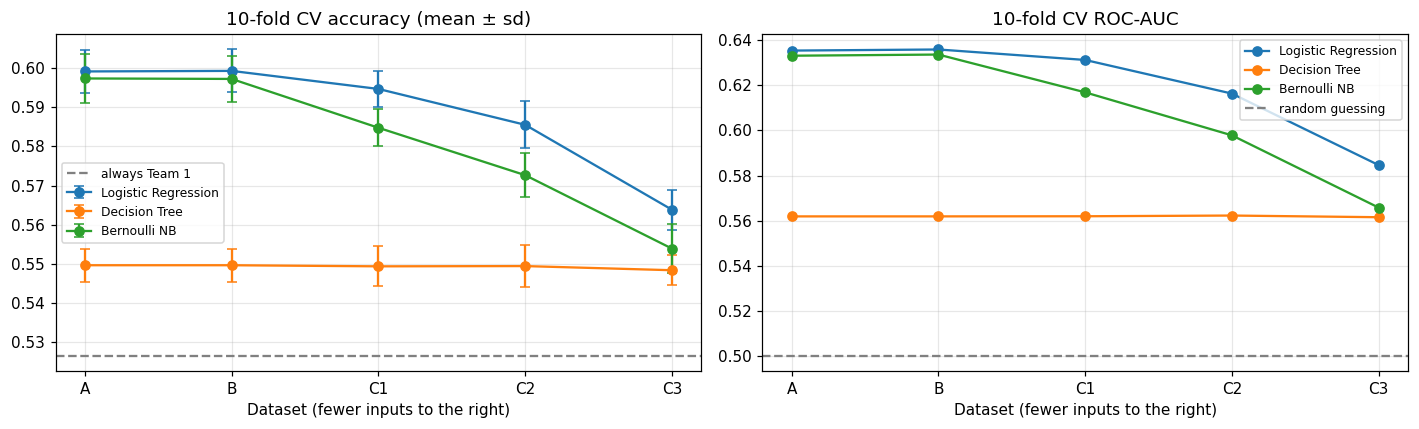

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = list(DATASETS)
for mname in SUBSET_MODELS:
    d = subset_tbl[subset_tbl.model == mname].set_index("dataset").loc[order]
    axes[0].errorbar(range(len(order)), d.cv_acc, yerr=d.cv_acc_sd, marker="o", capsize=3, label=mname)
    axes[1].plot(range(len(order)), d.cv_auc, marker="o", label=mname)
majority = y_train.mean()
axes[0].axhline(majority, color="grey", ls="--", label="always Team 1")
axes[1].axhline(0.5, color="grey", ls="--", label="random guessing")
for ax, t in zip(axes, ["10-fold CV accuracy (mean ± sd)", "10-fold CV ROC-AUC"]):
    ax.set_xticks(range(len(order))); ax.set_xticklabels([o.split(":")[0] for o in order]); ax.set_title(t); ax.legend(fontsize=8)
axes[0].set_xlabel("Dataset (fewer inputs to the right)"); axes[1].set_xlabel("Dataset (fewer inputs to the right)")
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_exp1_feature_subsets.png", dpi=150, bbox_inches="tight"); plt.show()

**Representation check (Logistic Regression, Dataset B):** signed hero columns vs the team-split representation. A change is adopted only if CV ROC-AUC improves by more than **0.002** (roughly the fold-to-fold noise).

In [22]:
rep_rows = [cv_evaluate(make_model(LogisticRegression(max_iter=2000, random_state=SEED), hero_repr=rep),
                        "Logistic Regression", "hero representation", settings=rep) for rep in ["signed", "team_split"]]
rep_tbl = pd.DataFrame(rep_rows); save(rep_tbl, "dota2_exp1b_representation")

# Decisions taken from Experiment 1 (computed, not typed in by hand):
lr_rows = subset_tbl[subset_tbl.model == "Logistic Regression"].set_index("dataset")
cluster_gain = lr_rows.loc["A: heroes+mode+type+cluster", "cv_auc"] - lr_rows.loc["B: heroes+mode+type", "cv_auc"]
rep_gain = rep_tbl.set_index("settings").loc["team_split", "cv_auc"] - rep_tbl.set_index("settings").loc["signed", "cv_auc"]
USE_CLUSTER = bool(cluster_gain > 0.002)
HERO_REPR = "team_split" if rep_gain > 0.002 else "signed"
BEST_PREP = dict(hero_repr=HERO_REPR, use_cluster=USE_CLUSTER)
print(f"Adding clusterid changes LR CV ROC-AUC by {cluster_gain:+.4f}  -> use_cluster = {USE_CLUSTER}")
print(f"Team-split instead of signed changes LR CV ROC-AUC by {rep_gain:+.4f} -> hero_repr = '{HERO_REPR}'")
print("Inputs used from here on (Decision Tree and Logistic Regression):", BEST_PREP, "= Dataset B, all heroes")
table(rep_rows, ["settings", "train_acc", "cv_acc", "cv_acc_sd", "F1", "cv_auc"], best_cols=["cv_acc", "cv_auc"])

Adding clusterid changes LR CV ROC-AUC by -0.0005  -> use_cluster = False
Team-split instead of signed changes LR CV ROC-AUC by -0.0010 -> hero_repr = 'signed'
Inputs used from here on (Decision Tree and Logistic Regression): {'hero_repr': 'signed', 'use_cluster': False} = Dataset B, all heroes


settings,train_acc,cv_acc,cv_acc_sd,F1,cv_auc
signed,0.6011,0.5993,0.0055,0.6402,0.6359
team_split,0.6032,0.5988,0.0042,0.6389,0.6349


Adding clusterid barely changes performance, which suggests that server region adds little useful information. Reducing Dataset B to the top 10 inputs lowers CV accuracy from 59.93% to 56.38% for Logistic Regression and from 59.72% to 55.39% for Naive Bayes, while the Decision Tree changes only slightly, from 54.97% to 54.84%. Naive Bayes is most affected and the tree is least affected, probably because the tree already relies on a few strong features, while the other models combine many small signals. We keep Dataset B with signed hero columns because it performs well without the extra cluster features; the reduced sets retain some predictive value but lose useful information.

&nbsp;

## 5. Experiment 2 — Decision Tree
### 5.1 Default tree (baseline)
A tree with scikit-learn's default settings grows until every leaf is pure, i.e. it can memorise the training data.

In [23]:
dt_default = make_model(DecisionTreeClassifier(random_state=SEED), **BEST_PREP)
r = cv_evaluate(dt_default, "Decision Tree (default)", "decision tree", settings="criterion=gini, max_depth=None, min_samples_leaf=1, min_samples_split=2")
print(f"Training accuracy {r['train_acc']:.4f} vs 10-fold CV accuracy {r['cv_acc']:.4f} ± {r['cv_acc_sd']:.4f} "
      f"(gap {r['overfit_gap']:.3f}) | CV ROC-AUC {r['cv_auc']:.4f}")
table([r], ["model"] + METRIC_COLS)

Training accuracy 1.0000 vs 10-fold CV accuracy 0.5222 ± 0.0061 (gap 0.478) | CV ROC-AUC 0.5211


model,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,F1,ROC_AUC
Decision Tree (default),0.5222,26464,21948,21920,22318,0.5425,0.4997,0.5466,0.5425,0.5446,0.5211


### 5.2 Manual parameter experiments
We change one idea at a time: limit the depth, require more matches per leaf, require more matches before a split, and switch the split criterion (Gini impurity vs entropy / information gain). Every row is 10-fold CV on the training data.

In [24]:
dt_configs = [
    ("DT 1", "gini", None, 1, 2),       # default (from 5.1)
    ("DT 2", "gini", 5, 1, 2),          # shallow tree
    ("DT 3", "gini", 10, 1, 2),
    ("DT 4", "gini", 10, 200, 2),       # depth + large leaves
    ("DT 5", "gini", 20, 500, 2),
    ("DT 6", "entropy", 20, 500, 2),    # other criterion
    ("DT 7", "gini", 20, 500, 2000),    # big minimum split size
    ("DT 8", "entropy", None, 1000, 2),
]
dt_rows = []
for label, crit, depth, leaf, split in dt_configs:
    clf = DecisionTreeClassifier(criterion=crit, max_depth=depth, min_samples_leaf=leaf, min_samples_split=split, random_state=SEED)
    r = cv_evaluate(make_model(clf, **BEST_PREP), label, "decision tree",
                    settings=f"criterion={crit}, max_depth={depth}, min_samples_leaf={leaf}, min_samples_split={split}")
    r.update(criterion=crit, max_depth=str(depth), min_samples_leaf=leaf, min_samples_split=split); dt_rows.append(r)
dt_tbl = pd.DataFrame(dt_rows); save(dt_tbl, "dota2_exp2_decision_tree_table")
table(dt_rows, ["model", "criterion", "max_depth", "min_samples_leaf", "min_samples_split", "train_acc", "cv_acc",
                "precision", "recall", "F1", "cv_auc", "overfit_gap"], best_cols=["cv_acc", "F1", "cv_auc"], lower_better=("overfit_gap",))

model,criterion,max_depth,min_samples_leaf,min_samples_split,train_acc,cv_acc,precision,recall,F1,cv_auc,overfit_gap
DT 1,gini,None,1,2,1.0000,0.5222,0.5466,0.5425,0.5446,0.5211,0.4778
DT 2,gini,5,1,2,0.5428,0.5371,0.5364,0.8890,0.6691,0.5431,0.0058
DT 3,gini,10,1,2,0.5677,0.5488,0.5540,0.7339,0.6314,0.5593,0.0189
DT 4,gini,10,200,2,0.5580,0.5497,0.5542,0.7396,0.6336,0.5619,0.0084
DT 5,gini,20,500,2,0.5652,0.5567,0.5685,0.6556,0.6090,0.5713,0.0085
DT 6,entropy,20,500,2,0.5652,0.5568,0.5686,0.6552,0.6088,0.5715,0.0085
DT 7,gini,20,500,2000,0.5651,0.5569,0.5687,0.6555,0.6091,0.5713,0.0082
DT 8,entropy,None,1000,2,0.5606,0.5554,0.5682,0.6487,0.6058,0.5678,0.0052


### 5.3 Automatic search (RandomizedSearchCV)
The search space is large (4 parameters), so 30 random combinations are tried instead of all of them, each with 10-fold CV, chosen by ROC-AUC.

In [25]:
dt_space = {"clf__criterion": ["gini", "entropy"],
            "clf__max_depth": [4, 6, 8, 10, 14, 18, 22, 26, None],
            "clf__min_samples_leaf": [20, 50, 100, 200, 300, 500, 800, 1200],
            "clf__min_samples_split": [2, 50, 200, 1000, 2000]}
t0 = time.perf_counter()
dt_search = RandomizedSearchCV(make_model(DecisionTreeClassifier(random_state=SEED), **BEST_PREP), dt_space, n_iter=30,
                               cv=CV10, scoring={"auc": "roc_auc", "acc": "accuracy"}, refit="auc", n_jobs=N_JOBS,
                               random_state=SEED, return_train_score=True)
dt_search.fit(X_train, y_train)
print(f"search time {time.perf_counter() - t0:.0f}s | best: {dt_search.best_params_} | CV ROC-AUC {dt_search.best_score_:.4f}")
sr = pd.DataFrame(dt_search.cv_results_)
search_tbl = pd.DataFrame({
    "criterion": sr.param_clf__criterion, "max_depth": sr.param_clf__max_depth.astype(str),
    "min_samples_leaf": sr.param_clf__min_samples_leaf, "min_samples_split": sr.param_clf__min_samples_split,
    "train_acc": sr.mean_train_acc, "cv_acc": sr.mean_test_acc, "cv_auc": sr.mean_test_auc, "cv_auc_sd": sr.std_test_auc,
}).sort_values("cv_auc", ascending=False)
save(search_tbl, "dota2_exp2_decision_tree_random_search")
table(search_tbl.head(10), list(search_tbl.columns), best_cols=["cv_acc", "cv_auc"])

search time 79s | best: {'clf__min_samples_split': 2, 'clf__min_samples_leaf': 300, 'clf__max_depth': None, 'clf__criterion': 'gini'} | CV ROC-AUC 0.5763


criterion,max_depth,min_samples_leaf,min_samples_split,train_acc,cv_acc,cv_auc,cv_auc_sd
gini,None,300,2,0.5725,0.5579,0.5763,0.0060
gini,22,200,2000,0.5721,0.5566,0.5736,0.0055
entropy,None,500,50,0.5656,0.5559,0.5732,0.0066
gini,22,100,2000,0.5749,0.5564,0.5723,0.0056
gini,None,50,1000,0.5907,0.5523,0.5719,0.0047
entropy,22,500,200,0.5654,0.5553,0.5718,0.0067
gini,26,100,200,0.5841,0.5567,0.5714,0.0059
gini,26,100,2,0.5841,0.5567,0.5714,0.0059
gini,None,20,1000,0.5952,0.5537,0.5713,0.0043
gini,18,100,1000,0.5731,0.5541,0.5686,0.0056


In [26]:
# Best tree, re-evaluated with the full set of metrics so it can enter the final comparison.
DT_BEST = {k.replace("clf__", ""): v for k, v in dt_search.best_params_.items()}
dt_best_model = make_model(DecisionTreeClassifier(random_state=SEED, **DT_BEST), **BEST_PREP)
dt_best_row = cv_evaluate(dt_best_model, "Decision Tree (tuned)", "final candidates", settings=str(DT_BEST))
table([r for r in CV_RESULTS if r["model"] in ("Decision Tree (default)", "Decision Tree (tuned)")],
      ["model", "train_acc", "cv_acc", "cv_acc_sd"] + METRIC_COLS[1:], best_cols=["cv_acc", "F1", "ROC_AUC"])

model,train_acc,cv_acc,cv_acc_sd,TP,FP,TN,FN,sensitivity,specificity,precision,recall,F1,ROC_AUC
Decision Tree (default),1.0000,0.5222,0.0061,26464,21948,21920,22318,0.5425,0.4997,0.5466,0.5425,0.5446,0.5211
Decision Tree (tuned),0.5725,0.5578,0.0054,31070,23261,20607,17712,0.6369,0.4698,0.5719,0.6369,0.6026,0.5761


### 5.4 How tree depth drives overfitting (graph)
Training vs 10-fold CV accuracy as `max_depth` grows, with all other settings at their defaults (so only depth changes).

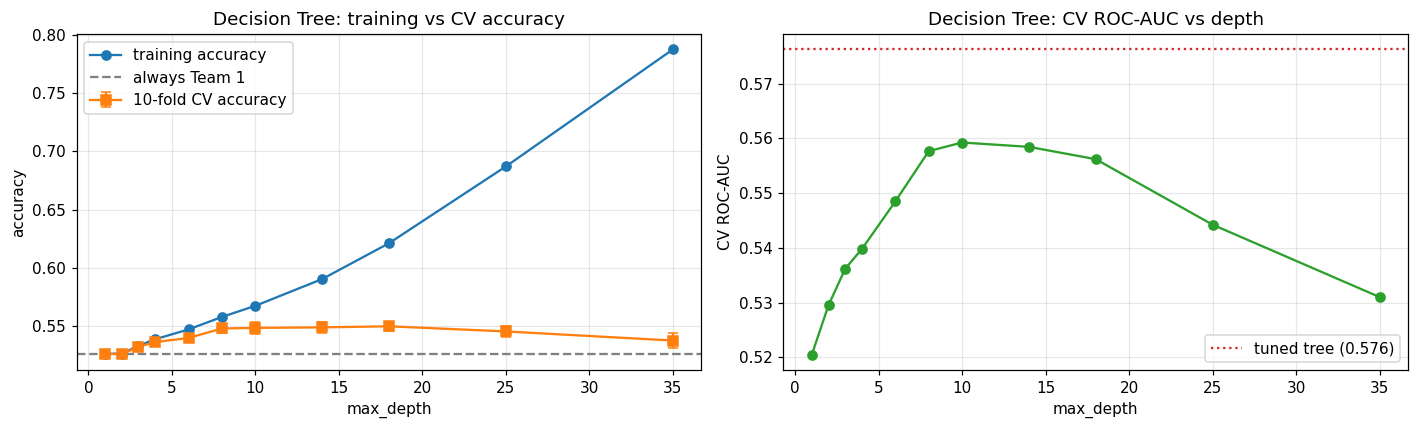

Best CV accuracy at depth 18; at depth 35 the train/CV gap is 0.249


In [27]:
depths = [1, 2, 3, 4, 6, 8, 10, 14, 18, 25, 35]
depth_rows = [cv_evaluate(make_model(DecisionTreeClassifier(max_depth=d, random_state=SEED), **BEST_PREP),
                          f"depth {d}", "tree depth curve", settings=f"max_depth={d}") for d in depths]
dc = pd.DataFrame(depth_rows); dc["depth"] = depths; save(dc, "dota2_exp2_depth_curve")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(dc.depth, dc.train_acc, "o-", label="training accuracy")
axes[0].errorbar(dc.depth, dc.cv_acc, yerr=dc.cv_acc_sd, fmt="s-", capsize=3, label="10-fold CV accuracy")
axes[0].axhline(y_train.mean(), color="grey", ls="--", label="always Team 1")
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Decision Tree: training vs CV accuracy"); axes[0].legend()
axes[1].plot(dc.depth, dc.cv_auc, "o-", color="tab:green")
axes[1].axhline(dt_best_row["cv_auc"], color="tab:red", ls=":", label=f"tuned tree ({dt_best_row['cv_auc']:.3f})")
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("CV ROC-AUC"); axes[1].set_title("Decision Tree: CV ROC-AUC vs depth"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_exp2_depth_overfitting.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Best CV accuracy at depth {dc.loc[dc.cv_acc.idxmax(), 'depth']}; at depth 35 the train/CV gap is {dc.overfit_gap.iloc[-1]:.3f}")

### 5.5 What does a decision path mean? (practical application, required by R3)
The tuned tree is too large to read, so a **depth-3 tree** (fixed settings, interpretation only, not a candidate model) is fitted on the team-split inputs, where each question is a plain "is hero X on Team 1 / Team 2?".

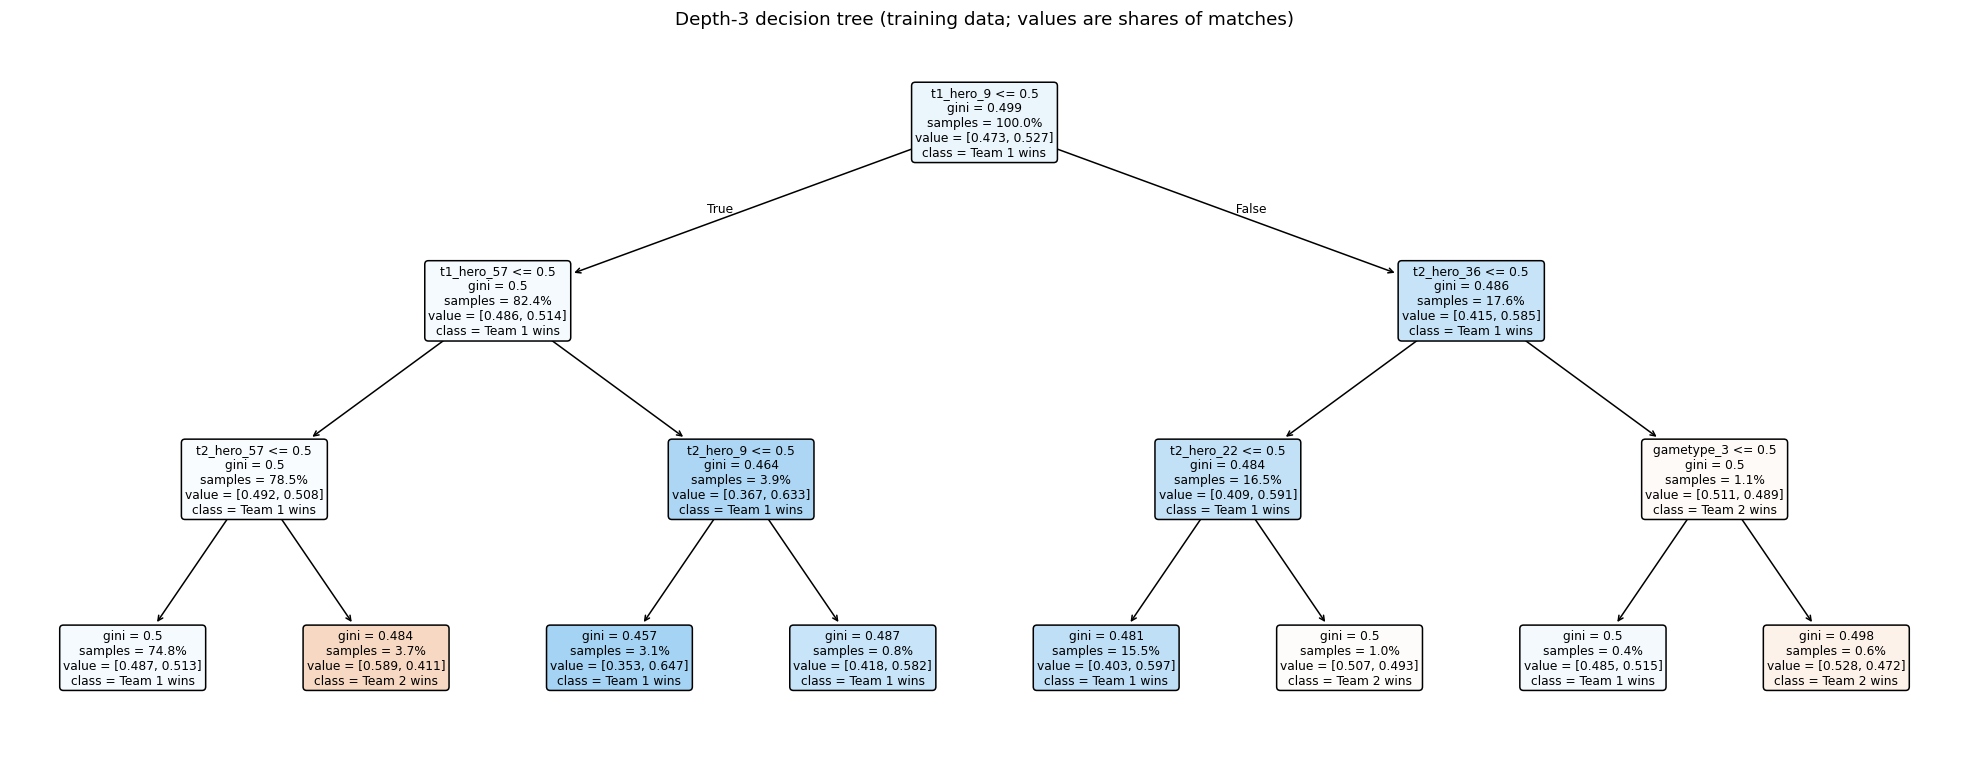

|--- t1_hero_9 <= 0.50
|   |--- t1_hero_57 <= 0.50
|   |   |--- t2_hero_57 <= 0.50
|   |   |   |--- class: 1
|   |   |--- t2_hero_57 >  0.50
|   |   |   |--- class: 0
|   |--- t1_hero_57 >  0.50
|   |   |--- t2_hero_9 <= 0.50
|   |   |   |--- class: 1
|   |   |--- t2_hero_9 >  0.50
|   |   |   |--- class: 1
|--- t1_hero_9 >  0.50
|   |--- t2_hero_36 <= 0.50
|   |   |--- t2_hero_22 <= 0.50
|   |   |   |--- class: 1
|   |   |--- t2_hero_22 >  0.50
|   |   |   |--- class: 0
|   |--- t2_hero_36 >  0.50
|   |   |--- gametype_3 <= 0.50
|   |   |   |--- class: 1
|   |   |--- gametype_3 >  0.50
|   |   |   |--- class: 0



Top 10 feature importances of the tuned tree:
hero_57    0.1449
hero_9     0.1332
hero_32    0.0566
hero_36    0.0558
hero_21    0.0549
hero_53    0.0527
hero_42    0.0377
hero_6     0.0347
hero_14    0.0294
hero_44    0.0286


In [28]:
shallow = make_model(DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=SEED), hero_repr="team_split")
shallow.fit(X_train, y_train)
fn = list(shallow.named_steps["prep"].get_feature_names_out())
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(shallow.named_steps["clf"], feature_names=fn, class_names=["Team 2 wins", "Team 1 wins"],
          filled=True, rounded=True, fontsize=8, ax=ax, proportion=True)
ax.set_title("Depth-3 decision tree (training data; values are shares of matches)")
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_decision_tree_depth3.png", dpi=150, bbox_inches="tight"); plt.show()
print(export_text(shallow.named_steps["clf"], feature_names=fn))
dt_imp = (pd.Series(dt_best_model.fit(X_train, y_train).named_steps["clf"].feature_importances_,
                    index=dt_best_model.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False))
print("Top 10 feature importances of the tuned tree:"); print(dt_imp.head(10).round(4).to_string())

Tree depth and minimum leaf size had the clearest effects because they control how easily the tree memorises individual matches. The default tree achieved 100% training accuracy but only 52.22% CV accuracy, while tuning improved CV accuracy to about 55.78%; changing the split size or using entropy instead of Gini made smaller differences in the tested settings. The depth graph shows that training accuracy keeps rising, but CV accuracy peaks around depth 18 and then falls as the tree overfits. One simple rule is: if Team 1 has neither hero 9 nor hero 57, and Team 2 has hero 57, predict Team 2 to win. This is only a weak draft hint because it ignores most other picks and information such as player skill.

&nbsp;

## 6. Experiment 3 — Linear models
### 6.1 Linear regression as a linear-separability check
We fit a linear regression on the training set (MSE) and check **linear separability**. If the classes were linearly separable, a linear model could reach (close to) 100 % *training* accuracy. For reference, a constant prediction of the Team 1 rate gives MSE = p(1 − p).

In [29]:
lin = make_model(LinearRegression(), **BEST_PREP)
lin.fit(X_train, y_train)
pred_tr = lin.predict(X_train)
mse_tr = mean_squared_error(y_train, pred_tr)
cv_mse, cv_acc_lin = [], []
for tr, va in CV10.split(X_train, y_train):
    m = clone(lin).fit(X_train.iloc[tr], y_train.iloc[tr]); p = m.predict(X_train.iloc[va])
    cv_mse.append(mean_squared_error(y_train.iloc[va], p)); cv_acc_lin.append(accuracy_score(y_train.iloc[va], p >= 0.5))
const_mse = y_train.mean() * (1 - y_train.mean())
linreg_tbl = pd.DataFrame([dict(model="constant (Team 1 rate)", train_MSE=const_mse, cv_MSE=const_mse,
                                train_acc=y_train.mean(), cv_acc=y_train.mean()),
                           dict(model="Linear Regression (threshold 0.5)", train_MSE=mse_tr, cv_MSE=np.mean(cv_mse),
                                train_acc=accuracy_score(y_train, pred_tr >= 0.5), cv_acc=np.mean(cv_acc_lin))])
save(linreg_tbl, "dota2_exp3_linear_regression")
linreg_tbl.round(4)

,model,train_MSE,cv_MSE,train_acc,cv_acc
0,constant (Team 1 rate),0.2493,0.2493,0.5265,0.5265
1,Linear Regression (threshold 0.5),0.2347,0.2352,0.6010,0.5992


### 6.2 Logistic Regression — regularisation strength `C` and solver / iterations
`C` controls how freely the weights may grow (small C = strong regularisation, simpler model). Training vs CV accuracy shows whether the model under- or overfits.

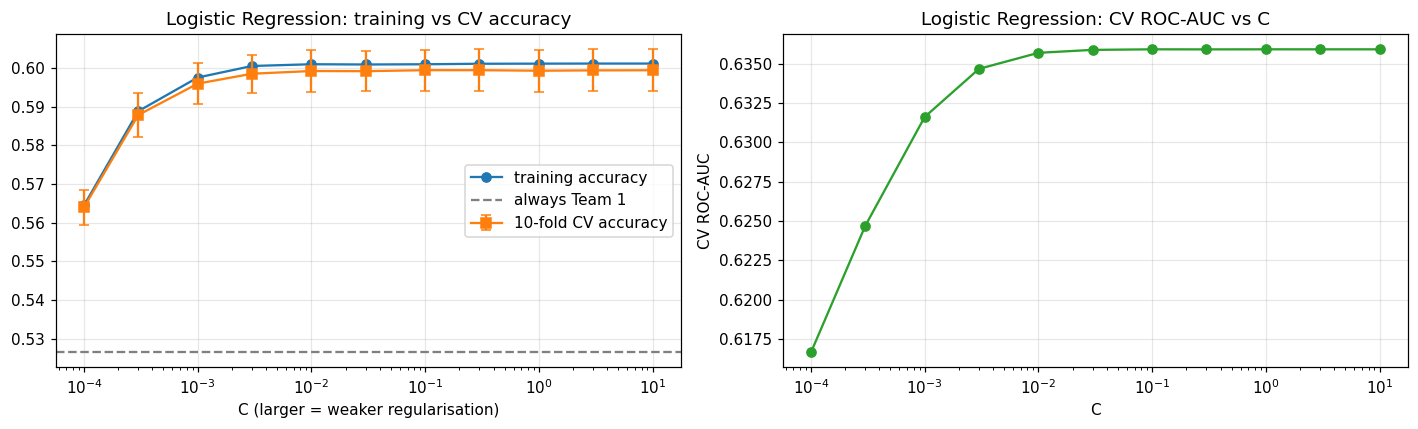

model,train_acc,cv_acc,cv_acc_sd,precision,recall,F1,cv_auc,overfit_gap,fit_s
LR C=0.0001,0.5645,0.5640,0.0045,0.5528,0.8991,0.6847,0.6166,0.0005,0.2318
LR C=0.0003,0.5888,0.5878,0.0057,0.5810,0.7792,0.6656,0.6247,0.0010,0.2396
LR C=0.001,0.5975,0.5959,0.0053,0.5968,0.7171,0.6514,0.6316,0.0016,0.2965
LR C=0.003,0.6005,0.5985,0.0049,0.6035,0.6921,0.6448,0.6347,0.0020,0.3257
LR C=0.01,0.6010,0.5992,0.0054,0.6060,0.6824,0.6420,0.6357,0.0018,0.3660
LR C=0.03,0.6009,0.5992,0.0052,0.6066,0.6789,0.6407,0.6359,0.0017,0.4011
LR C=0.1,0.6009,0.5994,0.0053,0.6072,0.6775,0.6404,0.6359,0.0015,0.4138
LR C=0.3,0.6011,0.5994,0.0054,0.6072,0.6772,0.6403,0.6359,0.0017,0.4163
LR C=1,0.6011,0.5993,0.0055,0.6071,0.6771,0.6402,0.6359,0.0018,0.4276
LR C=3,0.6011,0.5994,0.0054,0.6072,0.6771,0.6403,0.6359,0.0018,0.4240


In [30]:
C_values = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
lr_rows = []
for C in C_values:
    r = cv_evaluate(make_model(LogisticRegression(C=C, max_iter=2000, random_state=SEED), **BEST_PREP),
                    f"LR C={C}", "logistic regression C", settings=f"C={C}, solver=lbfgs")
    r["C"] = C; lr_rows.append(r)
lr_tbl = pd.DataFrame(lr_rows); save(lr_tbl, "dota2_exp3_logreg_C")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogx(lr_tbl.C, lr_tbl.train_acc, "o-", label="training accuracy")
axes[0].errorbar(lr_tbl.C, lr_tbl.cv_acc, yerr=lr_tbl.cv_acc_sd, fmt="s-", capsize=3, label="10-fold CV accuracy")
axes[0].axhline(y_train.mean(), color="grey", ls="--", label="always Team 1")
axes[0].set_xlabel("C (larger = weaker regularisation)"); axes[0].set_title("Logistic Regression: training vs CV accuracy"); axes[0].legend()
axes[1].semilogx(lr_tbl.C, lr_tbl.cv_auc, "o-", color="tab:green")
axes[1].set_xlabel("C"); axes[1].set_ylabel("CV ROC-AUC"); axes[1].set_title("Logistic Regression: CV ROC-AUC vs C")
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_exp3_logreg_C.png", dpi=150, bbox_inches="tight"); plt.show()
table(lr_rows, ["model", "train_acc", "cv_acc", "cv_acc_sd", "precision", "recall", "F1", "cv_auc", "overfit_gap", "fit_s"],
      best_cols=["cv_acc", "F1", "cv_auc"])

In [31]:
# Solver and number of iterations (with the best C). Too few iterations = the optimiser stops before convergence.
LR_C = float(lr_tbl.loc[lr_tbl.cv_auc.idxmax(), "C"])
solver_rows = []
for solver in ["lbfgs", "liblinear", "saga"]:
    for it in [5, 20, 100, 2000]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")      # 'did not converge' warnings are expected for very few iterations
            r = cv_evaluate(make_model(LogisticRegression(C=LR_C, solver=solver, max_iter=it, random_state=SEED), **BEST_PREP),
                            f"LR {solver}, {it} it.", "logistic regression solver", settings=f"C={LR_C}, solver={solver}, max_iter={it}")
        r.update(solver=solver, max_iter=it); solver_rows.append(r)
save(pd.DataFrame(solver_rows), "dota2_exp3_logreg_solver_iterations")
table(solver_rows, ["solver", "max_iter", "train_acc", "cv_acc", "F1", "cv_auc", "fit_s"], best_cols=["cv_acc", "cv_auc"], lower_better=("fit_s",))

solver,max_iter,train_acc,cv_acc,F1,cv_auc,fit_s
lbfgs,5,0.6006,0.5992,0.6382,0.6339,0.2084
lbfgs,20,0.6011,0.5993,0.6402,0.6359,0.4327
lbfgs,100,0.6011,0.5993,0.6402,0.6359,0.4217
lbfgs,2000,0.6011,0.5993,0.6402,0.6359,0.4683
liblinear,5,0.6011,0.5995,0.6403,0.6359,0.5206
liblinear,20,0.6011,0.5995,0.6403,0.6359,0.5121
liblinear,100,0.6011,0.5995,0.6403,0.6359,0.4567
liblinear,2000,0.6011,0.5995,0.6403,0.6359,0.5045
saga,5,0.5974,0.5960,0.6325,0.6319,0.4854
saga,20,0.6011,0.5994,0.6403,0.6359,1.7765


### 6.3 Learning rate, epochs and batch size (gradient-descent logistic regression)
`LogisticRegression` uses a solver with no learning rate. To study the learning settings, the same model is trained by **mini-batch stochastic gradient descent** (`SGDClassifier(loss="log_loss")` updated batch by batch). Each epoch shuffles the training data and takes one gradient step per batch of `batch_size` matches with step size `learning_rate`.

In [32]:
class MiniBatchLogReg(BaseEstimator, ClassifierMixin):
    """Logistic regression trained by mini-batch SGD (exposes learning_rate, epochs and batch_size)."""

    def __init__(self, learning_rate=0.01, epochs=5, batch_size=256, alpha=1e-4, random_state=SEED):
        self.learning_rate, self.epochs, self.batch_size, self.alpha, self.random_state = learning_rate, epochs, batch_size, alpha, random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=np.float64), np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        self.sgd_ = SGDClassifier(loss="log_loss", learning_rate="constant", eta0=self.learning_rate, alpha=self.alpha,
                                  random_state=self.random_state)
        self.classes_ = np.array([0, 1])
        for _ in range(self.epochs):
            idx = rng.permutation(len(y))
            for s in range(0, len(y), self.batch_size):
                b = idx[s:s + self.batch_size]
                self.sgd_.partial_fit(X[b], y[b], classes=self.classes_)
        return self

    def predict_proba(self, X):
        return self.sgd_.predict_proba(np.asarray(X, dtype=np.float64))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


sgd_grid = [(0.1, 5, 256), (0.01, 5, 256), (0.001, 5, 256), (0.0001, 5, 256),       # learning rate
            (0.001, 1, 256), (0.001, 20, 256),                                         # epochs
            (0.001, 5, 32), (0.001, 5, 4096)]                                          # batch size
sgd_rows = []
for lr_, ep, bs in sgd_grid:
    r = cv_evaluate(make_model(MiniBatchLogReg(learning_rate=lr_, epochs=ep, batch_size=bs), **BEST_PREP),
                    f"SGD lr={lr_}, ep={ep}, bs={bs}", "logistic regression SGD", settings=f"learning_rate={lr_}, epochs={ep}, batch_size={bs}")
    r.update(learning_rate=lr_, epochs=ep, batch_size=bs); sgd_rows.append(r)
save(pd.DataFrame(sgd_rows), "dota2_exp3_logreg_sgd")
table(sgd_rows, ["learning_rate", "epochs", "batch_size", "train_acc", "cv_acc", "cv_acc_sd", "F1", "cv_auc", "fit_s"],
      best_cols=["cv_acc", "F1", "cv_auc"])

learning_rate,epochs,batch_size,train_acc,cv_acc,cv_acc_sd,F1,cv_auc,fit_s
0.1000,5,256,0.5587,0.5566,0.0072,0.5812,0.5782,0.7418
0.0100,5,256,0.5921,0.5890,0.0049,0.6300,0.6236,0.7570
0.0010,5,256,0.6006,0.5983,0.0045,0.6438,0.6351,0.7885
0.0001,5,256,0.5940,0.5925,0.0059,0.6500,0.6268,0.7441
0.0010,1,256,0.5975,0.5951,0.0049,0.6464,0.6311,0.2289
0.0010,20,256,0.6008,0.5983,0.0050,0.6382,0.6349,2.5931
0.0010,5,32,0.6006,0.5983,0.0044,0.6442,0.6351,3.7139
0.0010,5,4096,0.6006,0.5983,0.0042,0.6438,0.6351,0.4367


Spearman correlation between LR hero weights and raw hero win-rates: 0.994


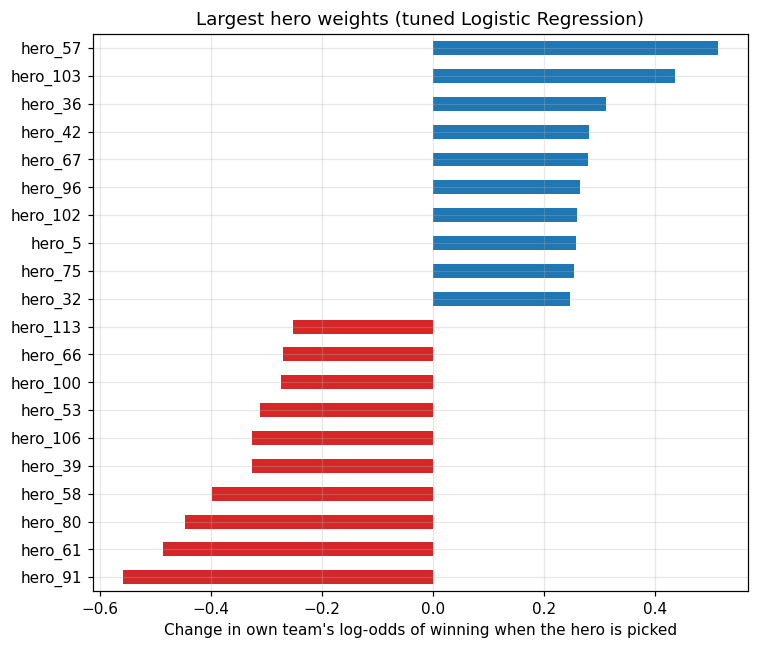

In [33]:
# Final Logistic Regression candidate = the best C from 6.2 with the lbfgs solver, evaluated with all metrics.
lr_best_model = make_model(LogisticRegression(C=LR_C, max_iter=2000, random_state=SEED), **BEST_PREP)
lr_best_row = cv_evaluate(lr_best_model, "Logistic Regression (tuned)", "final candidates", settings=f"C={LR_C}, solver=lbfgs")

# What did it learn? Effect of each hero on its own team's log-odds of winning.
lr_best_model.fit(X_train, y_train)
coef = pd.Series(lr_best_model.named_steps["clf"].coef_[0], index=lr_best_model.named_steps["prep"].get_feature_names_out())
if HERO_REPR == "signed":
    hero_effect = coef[coef.index.isin(USED_HEROES)]
else:
    hero_effect = pd.Series({h: (coef[f"t1_{h}"] - coef[f"t2_{h}"]) / 2 for h in USED_HEROES})
rho = stats.spearmanr(hero_effect[hero_stats.hero].to_numpy(), hero_stats.win_rate.to_numpy())[0]
print(f"Spearman correlation between LR hero weights and raw hero win-rates: {rho:.3f}")
top = pd.concat([hero_effect.nlargest(10), hero_effect.nsmallest(10)]).sort_values()
plt.figure(figsize=(7, 6)); top.plot(kind="barh", color=np.where(top > 0, "tab:blue", "tab:red"))
plt.xlabel("Change in own team's log-odds of winning when the hero is picked")
plt.title("Largest hero weights (tuned Logistic Regression)"); plt.tight_layout()
plt.savefig(FIG_DIR / "dota2_lr_hero_coefficients.png", dpi=150, bbox_inches="tight"); plt.show()

Both linear and logistic regression reach only about 60% training accuracy, suggesting that a simple linear boundary cannot cleanly separate the winners, although this alone does not prove non-separability. Very small values of C restrict Logistic Regression too much, while larger values produce similar results; the solvers also perform similarly once they have enough iterations. For gradient descent, a learning rate of 0.001 worked well, five epochs improved on one, and extra epochs or different batch sizes made little difference to accuracy. Training and CV accuracy are very close, so there is little evidence of overfitting, although much of the outcome remains unexplained. Positive hero weights favour the team picking that hero, while negative weights suggest the opposite, and their strong agreement with raw win-rates shows that both capture similar associations.

&nbsp;

## 7. Experiment 4 — Naive Bayes variants — the generative model
Naive Bayes models how each input is distributed **for each outcome** and combines them with Bayes' rule, assuming inputs are independent given the outcome. The variant must suit the data:

| Variant | Input given | Why |
|---|---|---|
| Multinomial NB | team-split 0/1 heroes + one-hot settings | **cannot** use the raw signed columns (−1 is not a valid count); 0/1 "counts" are valid |
| Complement NB | same as Multinomial | Multinomial variant designed for imbalanced classes |
| Bernoulli NB | same, as yes/no features | models presence **and** absence of each hero — the natural fit for picks |
| Categorical NB | signed hero columns recoded {−1, 0, +1} → {0, 1, 2} (heroes only) | treats each hero as a 3-category variable |
| Gaussian NB | signed hero columns as numbers | assumes bell-shaped values; a poor match for −1/0/+1 data (included as a contrast) |

In [34]:
to_categories = FunctionTransformer(lambda X: np.asarray(X) + 1)             # -1/0/+1 -> 0/1/2 for CategoricalNB
nb_models = {
    "Multinomial NB": make_model(MultinomialNB(alpha=1.0), hero_repr="team_split", use_cluster=USE_CLUSTER),
    "Complement NB": make_model(ComplementNB(alpha=1.0), hero_repr="team_split", use_cluster=USE_CLUSTER),
    "Bernoulli NB": make_model(BernoulliNB(alpha=1.0), hero_repr="team_split", use_cluster=USE_CLUSTER),
    "Categorical NB": Pipeline([("prep", make_preprocessor(hero_repr="signed", use_setup=False)), ("cat", to_categories),
                                ("clf", CategoricalNB(alpha=1.0, min_categories=3))]),
    "Gaussian NB": make_model(GaussianNB(), hero_repr="signed", use_cluster=USE_CLUSTER),
}
nb_rows = [cv_evaluate(m, n, "naive bayes variants", settings="alpha=1 (smoothing)" if n != "Gaussian NB" else "default")
           for n, m in nb_models.items()]
save(pd.DataFrame(nb_rows), "dota2_exp4_naive_bayes_variants")
table(nb_rows, ["model"] + METRIC_COLS, best_cols=METRIC_COLS[:1] + METRIC_COLS[5:], lower_better=())

model,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,F1,ROC_AUC
Multinomial NB,0.5977,33081,21568,22300,15701,0.6781,0.5083,0.6053,0.6781,0.6397,0.6340
Complement NB,0.5959,29008,17664,26204,19774,0.5946,0.5973,0.6215,0.5946,0.6078,0.6340
Bernoulli NB,0.5972,32824,21359,22509,15958,0.6729,0.5131,0.6058,0.6729,0.6376,0.6336
Categorical NB,0.5971,33032,21576,22292,15750,0.6771,0.5082,0.6049,0.6771,0.6390,0.6336
Gaussian NB,0.5609,29252,21156,22712,19530,0.5996,0.5177,0.5803,0.5996,0.5898,0.5757


In [35]:
# Smoothing (Laplace / Lidstone alpha) for the best variant by CV ROC-AUC.
best_nb_name = max(nb_rows, key=lambda r: r["cv_auc"])["model"]
print("Best variant by CV ROC-AUC:", best_nb_name)
alpha_rows = []
for a in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = clone(nb_models[best_nb_name]).set_params(clf__alpha=a)
    r = cv_evaluate(m, f"{best_nb_name} alpha={a}", "naive bayes alpha", settings=f"alpha={a}"); r["alpha"] = a; alpha_rows.append(r)
save(pd.DataFrame(alpha_rows), "dota2_exp4_naive_bayes_alpha")
NB_ALPHA = max(alpha_rows, key=lambda r: r["cv_auc"])["alpha"]
nb_best_model = clone(nb_models[best_nb_name]).set_params(clf__alpha=NB_ALPHA)
nb_best_row = cv_evaluate(nb_best_model, f"{best_nb_name} (tuned)", "final candidates", settings=f"alpha={NB_ALPHA}")
table(alpha_rows, ["alpha", "train_acc", "cv_acc", "F1", "cv_auc"], best_cols=["cv_acc", "F1", "cv_auc"])

Best variant by CV ROC-AUC: Multinomial NB


alpha,train_acc,cv_acc,F1,cv_auc
0.0010,0.6018,0.5977,0.6397,0.6340
0.0100,0.6018,0.5977,0.6397,0.6340
0.1000,0.6018,0.5977,0.6397,0.6340
1.0000,0.6018,0.5977,0.6397,0.6340
10.0000,0.6018,0.5976,0.6397,0.6340
100.0000,0.6019,0.5973,0.6417,0.6337


Multinomial Naive Bayes performed best by CV ROC-AUC, although Bernoulli and Categorical Naive Bayes were very close. Multinomial NB needs non-negative inputs, so the signed hero columns must be converted into separate yes/no columns for each team; Gaussian NB performed worse because hero picks do not follow a bell-shaped distribution. The independence assumption is unrealistic because each team must have exactly five heroes and some heroes are picked together or against each other. Smoothing made very little difference with 92,650 training matches, since the dataset already provides many observations.

&nbsp;

## 8. Ensembles and neural network — Random Forest, Extra Trees, MLP
**Why these models:** a single tree overfits (Section 5). A **Random Forest** averages many trees, each grown on a bootstrap sample with a random subset of features per split, which should lower variance. **Extra Trees** also randomise the split thresholds. An **MLP** (multi-layer perceptron) can learn hero *interactions* (synergies / counters) that additive models cannot, so it can test whether hero interactions matter. Inputs need no scaling: heroes are already −1/0/+1 and the settings are one-hot.

In [36]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

# Each forest uses 1 core because cv_evaluate already runs the 10 folds in parallel (avoids over-subscribing the CPU).
rf_configs = [  # (label, n_estimators, max_depth, min_samples_leaf, max_features)
    ("RF 1", 100, 12, 20, "sqrt"),
    ("RF 2", 100, 20, 20, "sqrt"),
    ("RF 3", 100, 20, 50, "sqrt"),
    ("RF 4", 200, None, 50, "sqrt"),    # more, fully grown trees with large leaves
    ("RF 5", 200, None, 20, "log2"),    # fewer features per split = more random trees
]
rf_rows = []
for label, n, d, leaf, mf in rf_configs:
    clf = RandomForestClassifier(n_estimators=n, max_depth=d, min_samples_leaf=leaf, max_features=mf, random_state=SEED, n_jobs=1)
    r = cv_evaluate(make_model(clf, **BEST_PREP), label, "random forest",
                    settings=f"n_estimators={n}, max_depth={d}, min_samples_leaf={leaf}, max_features={mf}")
    r.update(n_estimators=n, max_depth=str(d), min_samples_leaf=leaf, max_features=mf); rf_rows.append(r)
save(pd.DataFrame(rf_rows), "dota2_exp5_random_forest")
table(rf_rows + [dt_best_row], ["model", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "train_acc", "cv_acc",
                                "cv_acc_sd", "precision", "recall", "F1", "cv_auc", "overfit_gap", "fit_s"],
      best_cols=["cv_acc", "F1", "cv_auc"], lower_better=("overfit_gap",))

model,n_estimators,max_depth,min_samples_leaf,max_features,train_acc,cv_acc,cv_acc_sd,precision,recall,F1,cv_auc,overfit_gap,fit_s
RF 1,100.0000,12,20.0000,sqrt,0.5893,0.5702,0.0030,0.5610,0.8450,0.6743,0.6072,0.0191,5.5275
RF 2,100.0000,20,20.0000,sqrt,0.6201,0.5804,0.0046,0.5747,0.7811,0.6622,0.6145,0.0397,8.4663
RF 3,100.0000,20,50.0000,sqrt,0.6033,0.5791,0.0048,0.5735,0.7824,0.6618,0.6121,0.0242,7.9775
RF 4,200.0000,None,50.0000,sqrt,0.6247,0.5866,0.0048,0.5860,0.7323,0.6510,0.6185,0.0380,17.5872
RF 5,200.0000,None,20.0000,log2,0.6651,0.5896,0.0030,0.5868,0.7451,0.6566,0.6256,0.0755,11.6132
Decision Tree (tuned),nan,nan,nan,nan,0.5725,0.5578,0.0054,0.5719,0.6369,0.6026,0.5763,0.0147,1.0020


In [37]:
et_configs = [("ET 1", 100, 12, 10), ("ET 2", 100, 20, 10), ("ET 3", 100, 20, 30)]
et_rows = []
for label, n, d, leaf in et_configs:
    clf = ExtraTreesClassifier(n_estimators=n, max_depth=d, min_samples_leaf=leaf, random_state=SEED, n_jobs=1)
    r = cv_evaluate(make_model(clf, **BEST_PREP), label, "extra trees", settings=f"n_estimators={n}, max_depth={d}, min_samples_leaf={leaf}")
    r.update(n_estimators=n, max_depth=str(d), min_samples_leaf=leaf); et_rows.append(r)
save(pd.DataFrame(et_rows), "dota2_exp5_extra_trees")
table(et_rows, ["model", "n_estimators", "max_depth", "min_samples_leaf", "train_acc", "cv_acc", "cv_acc_sd", "F1", "cv_auc", "overfit_gap", "fit_s"],
      best_cols=["cv_acc", "F1", "cv_auc"], lower_better=("overfit_gap",))

model,n_estimators,max_depth,min_samples_leaf,train_acc,cv_acc,cv_acc_sd,F1,cv_auc,overfit_gap,fit_s
ET 1,100,12,10,0.5947,0.5684,0.0036,0.6771,0.6090,0.0263,8.9895
ET 2,100,20,10,0.6430,0.5796,0.0044,0.6627,0.6147,0.0634,13.5800
ET 3,100,20,30,0.6135,0.5802,0.0043,0.6641,0.6135,0.0334,14.8228


In [38]:
# Best forest of each kind -> final candidates; compare what the forest and the single tree rely on.
def best_of(rows):
    return max(rows, key=lambda r: r["cv_auc"])


rf_pick, et_pick = best_of(rf_rows), best_of(et_rows)
RF_BEST = dict(n_estimators=rf_pick["n_estimators"], max_depth=None if rf_pick["max_depth"] == "None" else int(rf_pick["max_depth"]),
               min_samples_leaf=rf_pick["min_samples_leaf"], max_features=rf_pick["max_features"])
ET_BEST = dict(n_estimators=et_pick["n_estimators"], max_depth=None if et_pick["max_depth"] == "None" else int(et_pick["max_depth"]),
               min_samples_leaf=et_pick["min_samples_leaf"])
rf_best_model = make_model(RandomForestClassifier(random_state=SEED, n_jobs=1, **RF_BEST), **BEST_PREP)
et_best_model = make_model(ExtraTreesClassifier(random_state=SEED, n_jobs=1, **ET_BEST), **BEST_PREP)
rf_best_row = dict(rf_pick, model="Random Forest (tuned)", experiment="final candidates", settings=str(RF_BEST))
et_best_row = dict(et_pick, model="Extra Trees (tuned)", experiment="final candidates", settings=str(ET_BEST))
print("Best Random Forest:", RF_BEST, f"| CV acc {rf_pick['cv_acc']:.4f}, CV AUC {rf_pick['cv_auc']:.4f}, train-CV gap {rf_pick['overfit_gap']:.3f}")
print("Best Extra Trees  :", ET_BEST, f"| CV acc {et_pick['cv_acc']:.4f}, CV AUC {et_pick['cv_auc']:.4f}, train-CV gap {et_pick['overfit_gap']:.3f}")
print(f"Tuned single tree : CV acc {dt_best_row['cv_acc']:.4f}, CV AUC {dt_best_row['cv_auc']:.4f}, train-CV gap {dt_best_row['overfit_gap']:.3f}")

rf_fit = clone(rf_best_model).fit(X_train, y_train)
rf_imp = pd.Series(rf_fit.named_steps["clf"].feature_importances_, index=rf_fit.named_steps["prep"].get_feature_names_out())
imp_cmp = pd.DataFrame({"tree_feature": dt_imp.head(10).index, "tree_importance": dt_imp.head(10).values,
                        "forest_feature": rf_imp.sort_values(ascending=False).head(10).index,
                        "forest_importance": rf_imp.sort_values(ascending=False).head(10).values})
rho_imp = stats.spearmanr(rf_imp[dt_imp.index], dt_imp)[0]
print(f"Spearman correlation of feature importances, forest vs single tree: {rho_imp:.3f}")
save(imp_cmp, "dota2_exp5_importance_tree_vs_forest")
imp_cmp.round(4)

Best Random Forest: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'log2'} | CV acc 0.5896, CV AUC 0.6256, train-CV gap 0.076
Best Extra Trees  : {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 10} | CV acc 0.5796, CV AUC 0.6147, train-CV gap 0.063
Tuned single tree : CV acc 0.5578, CV AUC 0.5763, train-CV gap 0.015


Spearman correlation of feature importances, forest vs single tree: 0.808


,tree_feature,tree_importance,forest_feature,forest_importance
0,hero_57,0.1449,hero_9,0.0447
1,hero_9,0.1332,hero_57,0.0421
2,hero_32,0.0566,hero_21,0.0296
3,hero_36,0.0558,hero_32,0.0239
4,hero_21,0.0549,hero_53,0.0235
5,hero_53,0.0527,hero_36,0.0219
6,hero_42,0.0377,hero_74,0.0214
7,hero_6,0.0347,hero_42,0.0200
8,hero_14,0.0294,hero_106,0.0195
9,hero_44,0.0286,hero_18,0.0190


### 8.2 MLP — architecture experiments
All use the Adam optimiser and **early stopping** (10 % of each training fold is held back inside the network's training; training stops after 10 epochs without improvement). We vary depth, width, activation and learning rate.

In [39]:
mlp_configs = [  # (label, hidden layers, activation, learning_rate_init)
    ("MLP 1", (16,), "relu", 0.001),
    ("MLP 2", (32,), "relu", 0.001),
    ("MLP 3", (64,), "relu", 0.001),
    ("MLP 4", (64, 32), "relu", 0.001),
    ("MLP 5", (128, 64, 32), "relu", 0.001),
    ("MLP 6", (64, 32), "tanh", 0.001),
    ("MLP 7", (64, 32), "relu", 0.01),
]
mlp_rows = []
for label, hl, act, lr0 in mlp_configs:
    clf = MLPClassifier(hidden_layer_sizes=hl, activation=act, learning_rate_init=lr0, early_stopping=True,
                        n_iter_no_change=10, max_iter=150, random_state=SEED)
    r = cv_evaluate(make_model(clf, **BEST_PREP), label, "mlp architecture",
                    settings=f"hidden={hl}, activation={act}, learning_rate={lr0}, early_stopping=True")
    r.update(hidden_layers=str(hl), activation=act, learning_rate=lr0); mlp_rows.append(r)
save(pd.DataFrame(mlp_rows), "dota2_exp6_mlp_architectures")
table(mlp_rows, ["model", "hidden_layers", "activation", "learning_rate"] + METRIC_COLS + ["train_acc", "overfit_gap", "fit_s"],
      best_cols=["accuracy", "specificity", "precision", "F1", "ROC_AUC"], lower_better=("overfit_gap",))

model,hidden_layers,activation,learning_rate,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,F1,ROC_AUC,train_acc,overfit_gap,fit_s
MLP 1,"(16,)",relu,0.0010,0.5965,32487,21092,22776,16295,0.6660,0.5192,0.6063,0.6660,0.6348,0.6310,0.6092,0.0127,1.5575
MLP 2,"(32,)",relu,0.0010,0.5955,32594,21287,22581,16188,0.6682,0.5147,0.6049,0.6682,0.6350,0.6310,0.6093,0.0138,1.5597
MLP 3,"(64,)",relu,0.0010,0.5953,31786,20496,23372,16996,0.6516,0.5328,0.6080,0.6516,0.6290,0.6303,0.6114,0.0161,2.2689
MLP 4,"(64, 32)",relu,0.0010,0.5925,31229,20205,23663,17553,0.6402,0.5394,0.6072,0.6402,0.6232,0.6286,0.6101,0.0176,2.6821
MLP 5,"(128, 64, 32)",relu,0.0010,0.5957,31275,19948,23920,17507,0.6411,0.5453,0.6106,0.6411,0.6255,0.6303,0.6087,0.0130,4.7516
MLP 6,"(64, 32)",tanh,0.0010,0.5968,31748,20324,23544,17034,0.6508,0.5367,0.6097,0.6508,0.6296,0.6316,0.6056,0.0088,3.5912
MLP 7,"(64, 32)",relu,0.0100,0.5936,32073,20945,22923,16709,0.6575,0.5225,0.6049,0.6575,0.6301,0.6297,0.6078,0.0142,2.3867


### 8.3 MLP overfitting experiment and how to stop it
A large network (128-64) is trained **without** early stopping for 40 epochs, then the two standard fixes are applied: early stopping, and a stronger L2 penalty (`alpha`).

model,train_acc,cv_acc,cv_acc_sd,overfit_gap,F1,cv_auc
"MLP big, no early stopping",0.8094,0.5456,0.0039,0.2638,0.5720,0.5620
MLP big + early stopping,0.6106,0.5940,0.0053,0.0166,0.6276,0.6294
MLP big + strong L2 (alpha=1),0.5999,0.5973,0.0057,0.0026,0.6401,0.6339


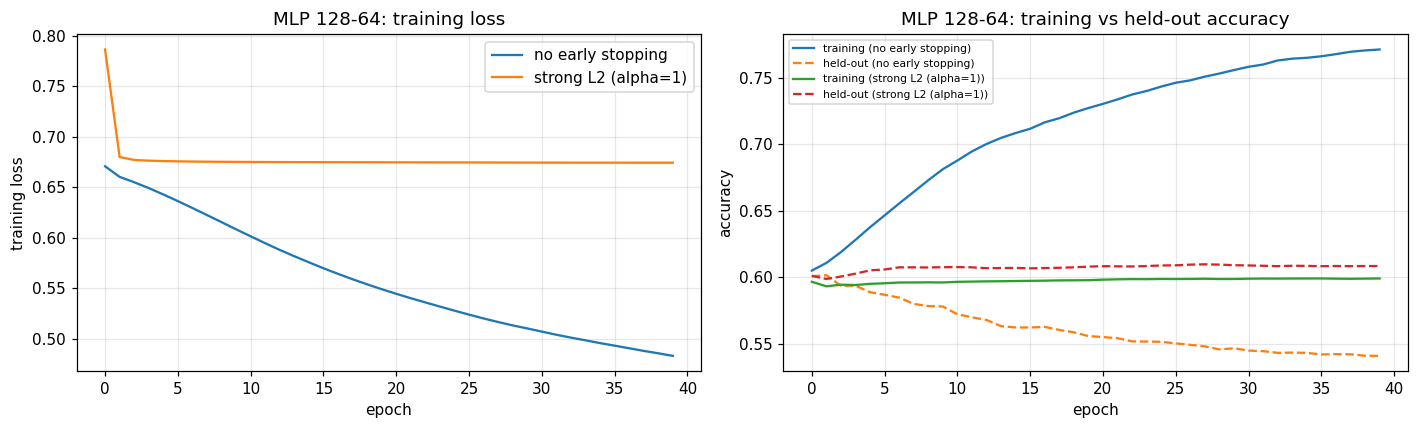

Without regularisation, held-out accuracy peaks at epoch 2 (0.6015) and is 0.5409 after 40 epochs, while training accuracy reaches 0.7713.


In [40]:
big = dict(hidden_layer_sizes=(128, 64), random_state=SEED)
of_configs = [("MLP big, no early stopping", dict(early_stopping=False, max_iter=40, alpha=1e-4)),
              ("MLP big + early stopping", dict(early_stopping=True, n_iter_no_change=10, max_iter=40, alpha=1e-4)),
              ("MLP big + strong L2 (alpha=1)", dict(early_stopping=False, max_iter=40, alpha=1.0))]
of_rows = []
for label, kw in of_configs:
    r = cv_evaluate(make_model(MLPClassifier(**big, **kw), **BEST_PREP), label, "mlp overfitting", settings=str(kw))
    of_rows.append(r)
save(pd.DataFrame(of_rows), "dota2_exp6_mlp_overfitting")
display(table(of_rows, ["model", "train_acc", "cv_acc", "cv_acc_sd", "overfit_gap", "F1", "cv_auc"],
              best_cols=["cv_acc", "cv_auc"], lower_better=("overfit_gap",)))

# Learning curves on one 90/10 split of the training data: training loss and held-out accuracy per epoch.
Xa, Xh, ya, yh = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED)
prep = make_preprocessor(**BEST_PREP).fit(Xa)
Za, Zh = prep.transform(Xa), prep.transform(Xh)
N_EPOCHS = 40
curves = {}
for label, kw in [("no early stopping", dict(alpha=1e-4)), ("strong L2 (alpha=1)", dict(alpha=1.0))]:
    net = MLPClassifier(**big, **kw, max_iter=1, warm_start=True)
    loss, tr_acc, ho_acc = [], [], []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        for epoch in range(N_EPOCHS):
            net.fit(Za, ya)
            loss.append(net.loss_); tr_acc.append(net.score(Za, ya)); ho_acc.append(net.score(Zh, yh))
    curves[label] = (loss, tr_acc, ho_acc)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, (loss, tr_acc, ho_acc) in curves.items():
    axes[0].plot(loss, label=label)
    axes[1].plot(tr_acc, "-", label=f"training ({label})"); axes[1].plot(ho_acc, "--", label=f"held-out ({label})")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("MLP 128-64: training loss"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("MLP 128-64: training vs held-out accuracy"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_exp6_mlp_overfitting.png", dpi=150, bbox_inches="tight"); plt.show()
best_ho = int(np.argmax(curves["no early stopping"][2]))
print(f"Without regularisation, held-out accuracy peaks at epoch {best_ho + 1} ({curves['no early stopping'][2][best_ho]:.4f}) "
      f"and is {curves['no early stopping'][2][-1]:.4f} after {N_EPOCHS} epochs, while training accuracy reaches {curves['no early stopping'][1][-1]:.4f}.")

In [41]:
# Best MLP (by CV ROC-AUC) -> final candidate.
mlp_pick = best_of(mlp_rows)
import ast
MLP_BEST = dict(hidden_layer_sizes=ast.literal_eval(mlp_pick["hidden_layers"]), activation=mlp_pick["activation"],
                learning_rate_init=mlp_pick["learning_rate"], early_stopping=True, n_iter_no_change=10, max_iter=150)
mlp_best_model = make_model(MLPClassifier(random_state=SEED, **MLP_BEST), **BEST_PREP)
mlp_best_row = dict(mlp_pick, model="MLP (tuned)", experiment="final candidates", settings=str(MLP_BEST))
print("Best MLP:", MLP_BEST, f"| CV acc {mlp_pick['cv_acc']:.4f}, CV AUC {mlp_pick['cv_auc']:.4f}")

EXTRA_CANDIDATES = {
    "Random Forest (tuned)": (rf_best_model, rf_best_row),
    "Extra Trees (tuned)": (et_best_model, et_best_row),
    "MLP (tuned)": (mlp_best_model, mlp_best_row),
}

Best MLP: {'hidden_layer_sizes': (64, 32), 'activation': 'tanh', 'learning_rate_init': 0.001, 'early_stopping': True, 'n_iter_no_change': 10, 'max_iter': 150} | CV acc 0.5968, CV AUC 0.6324


Random Forest achieved higher CV accuracy than the tuned single tree (58.96% versus 55.78%), but its larger training–CV gap means it still showed more overfitting than the tuned tree. Both models relied on similar heroes, especially hero 9 and hero 57. Among the architecture experiments, the MLP with 64 and 32 hidden units and tanh activation performed best, while adding more layers or units did not consistently improve results. The large network without early stopping strongly overfit; both early stopping and stronger L2 regularisation helped, with stronger L2 giving the best results in that experiment. The MLP did not beat Logistic Regression, which suggests that these more complex models add little benefit, without proving that hero interactions do not matter.

&nbsp;

## 9. Final evaluation on the official test set (used once)
All settings are now fixed. Each final model is **refitted on all 92,650 training matches** and scored **once** on the 10,294 unseen test matches.

In [42]:
FINAL_CANDIDATES = {
    "Majority class (always Team 1)": (DummyClassifier(strategy="most_frequent"),
                                       cv_evaluate(DummyClassifier(strategy="most_frequent"), "Majority class (always Team 1)", "final candidates", settings="-")),
    "Decision Tree (tuned)": (dt_best_model, dt_best_row),
    "Logistic Regression (tuned)": (lr_best_model, lr_best_row),
    f"{best_nb_name} (tuned)": (nb_best_model, nb_best_row),
}
FINAL_CANDIDATES.update(EXTRA_CANDIDATES)

final_rows, test_rows, fitted, test_proba = [], [], {}, {}
for name, (model, cvr) in FINAL_CANDIDATES.items():
    m = clone(model)
    t0 = time.perf_counter(); m.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    proba = m.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
    fitted[name], test_proba[name] = m, proba
    tm = eval_metrics(y_test, pred, proba)
    test_rows.append(dict(model=name, **tm))
    final_rows.append(dict(model=name, best_settings=cvr["settings"], train_acc=accuracy_score(y_train, m.predict(X_train)),
                           cv_acc=f"{cvr['cv_acc']:.4f} ± {cvr['cv_acc_sd']:.4f}", cv_precision=cvr["precision"],
                           cv_recall=cvr["recall"], cv_F1=cvr["F1"], cv_ROC_AUC=cvr["cv_auc"],
                           test_acc=tm["accuracy"], test_F1=tm["F1"], test_ROC_AUC=tm["ROC_AUC"], fit_s=fit_s))
final_tbl = pd.DataFrame(final_rows); save(final_tbl, "dota2_final_comparison")
test_tbl = pd.DataFrame(test_rows); save(test_tbl, "dota2_final_test_eval_metrics")
print("FINAL COMPARISON (CV = 10-fold on training data; test = official test set, used once)")
table(final_rows, list(final_tbl.columns), best_cols=["cv_precision", "cv_recall", "cv_F1", "cv_ROC_AUC", "test_acc", "test_F1", "test_ROC_AUC"])

FINAL COMPARISON (CV = 10-fold on training data; test = official test set, used once)


model,best_settings,train_acc,cv_acc,cv_precision,cv_recall,cv_F1,cv_ROC_AUC,test_acc,test_F1,test_ROC_AUC,fit_s
Majority class (always Team 1),-,0.5265,0.5265 ± 0.0000,0.5265,1.0000,0.6898,0.5000,0.5345,0.6966,0.5000,0.0012
Decision Tree (tuned),"{'min_samples_split': 2, 'min_samples_leaf': 300, 'max_depth': None, 'criterion': 'gini'}",0.5732,0.5578 ± 0.0054,0.5719,0.6369,0.6026,0.5763,0.5608,0.6096,0.5772,0.7195
Logistic Regression (tuned),"C=1.0, solver=lbfgs",0.6011,0.5993 ± 0.0055,0.6071,0.6771,0.6402,0.6359,0.5973,0.6393,0.6346,0.1905
Multinomial NB (tuned),alpha=10,0.6009,0.5976 ± 0.0056,0.6052,0.6784,0.6397,0.6340,0.5960,0.6404,0.6329,0.1323
Random Forest (tuned),"{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'log2'}",0.6650,0.5896 ± 0.0030,0.5868,0.7451,0.6566,0.6256,0.5907,0.6601,0.6260,9.8695
Extra Trees (tuned),"{'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 10}",0.6402,0.5796 ± 0.0044,0.5737,0.7844,0.6627,0.6147,0.5819,0.6656,0.6134,9.6727
MLP (tuned),"{'hidden_layer_sizes': (64, 32), 'activation': 'tanh', 'learning_rate_init': 0.001, 'early_stopping': True, 'n_iter_no_change': 10, 'max_iter': 150}",0.5994,0.5968 ± 0.0056,0.6097,0.6508,0.6296,0.6324,0.5930,0.6385,0.6325,3.0752


In [43]:
print("All metrics on the official test set (10,294 matches):")
table(test_rows, ["model"] + METRIC_COLS, best_cols=["accuracy", "specificity", "precision", "F1", "ROC_AUC"])

All metrics on the official test set (10,294 matches):


model,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,F1,ROC_AUC
Majority class (always Team 1),0.5345,5502,4792,0,0,1.0000,0.0000,0.5345,1.0000,0.6966,0.5000
Decision Tree (tuned),0.5608,3529,2548,2244,1973,0.6414,0.4683,0.5807,0.6414,0.6096,0.5772
Logistic Regression (tuned),0.5973,3673,2316,2476,1829,0.6676,0.5167,0.6133,0.6676,0.6393,0.6346
Multinomial NB (tuned),0.5960,3703,2360,2432,1799,0.6730,0.5075,0.6108,0.6730,0.6404,0.6329
Random Forest (tuned),0.5907,4090,2801,1991,1412,0.7434,0.4155,0.5935,0.7434,0.6601,0.6260
Extra Trees (tuned),0.5819,4284,3086,1706,1218,0.7786,0.3560,0.5813,0.7786,0.6656,0.6134
MLP (tuned),0.5930,3701,2389,2403,1801,0.6727,0.5015,0.6077,0.6727,0.6385,0.6325


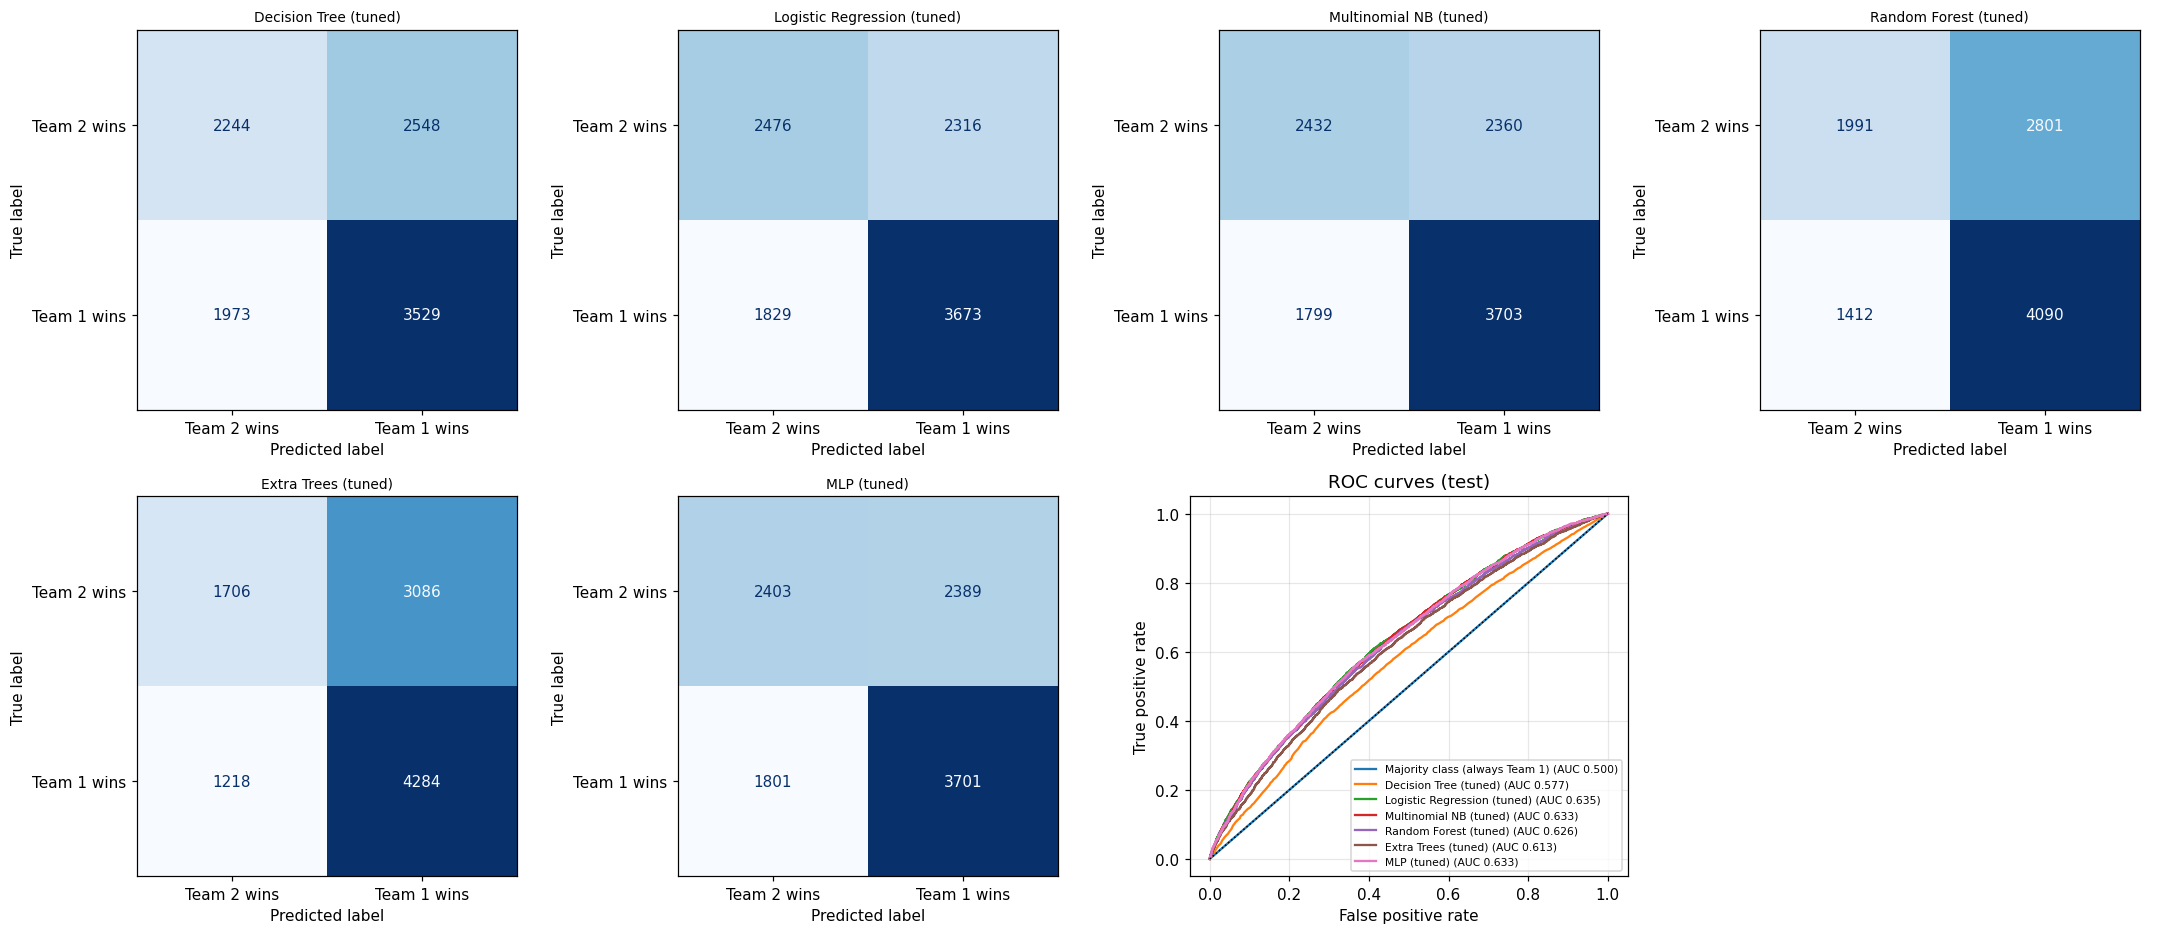

In [44]:
# Confusion matrices and ROC curves on the test set.
models_no_dummy = [n for n in fitted if not n.startswith("Majority")]
n_pan = len(models_no_dummy) + 1; n_col = 4; n_row = int(np.ceil(n_pan / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(5 * n_col, 4.3 * n_row)); axes = np.atleast_1d(axes).ravel()
for ax in axes[n_pan:]:
    ax.axis("off")
axes = axes[:n_pan]
for ax, name in zip(axes, models_no_dummy):
    ConfusionMatrixDisplay.from_predictions(y_test, (test_proba[name] >= 0.5).astype(int),
                                            display_labels=["Team 2 wins", "Team 1 wins"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=9); ax.grid(False)
for name in fitted:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[-1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, test_proba[name]):.3f})")
axes[-1].plot([0, 1], [0, 1], "k:", lw=1); axes[-1].set_xlabel("False positive rate"); axes[-1].set_ylabel("True positive rate")
axes[-1].set_title("ROC curves (test)"); axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_final_confusion_roc.png", dpi=150, bbox_inches="tight"); plt.show()

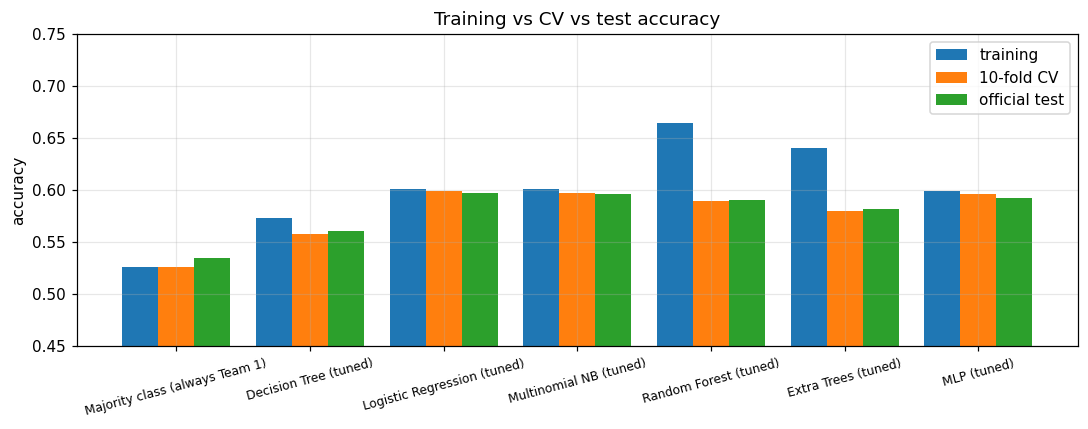

In [45]:
# Training vs cross-validation vs test accuracy (overfitting / generalisation at a glance).
ft = final_tbl.copy(); ft["cv_acc_mean"] = [FINAL_CANDIDATES[n][1]["cv_acc"] for n in ft.model]
x = np.arange(len(ft)); w = 0.27
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w, ft.train_acc, w, label="training"); ax.bar(x, ft.cv_acc_mean, w, label="10-fold CV"); ax.bar(x + w, ft.test_acc, w, label="official test")
ax.set_xticks(x); ax.set_xticklabels(ft.model, rotation=15, fontsize=8); ax.set_ylim(0.45, max(0.75, ft.train_acc.max() + 0.02))
ax.set_ylabel("accuracy"); ax.set_title("Training vs CV vs test accuracy"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_final_train_cv_test.png", dpi=150, bbox_inches="tight"); plt.show()

In [46]:
# Are the differences bigger than chance? Exact McNemar-style test on the matches where two models disagree,
# and a one-sided test of each model against the 'always Team 1' accuracy.
truth = y_test.to_numpy()
preds = {n: (p >= 0.5).astype(int) for n, p in test_proba.items()}
for i, a in enumerate(models_no_dummy):
    for b in models_no_dummy[i + 1:]:
        only_a = int(((preds[a] == truth) & (preds[b] != truth)).sum()); only_b = int(((preds[a] != truth) & (preds[b] == truth)).sum())
        p = stats.binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        print(f"{a} vs {b}: right only for first {only_a}, only for second {only_b}, p = {p:.2e}")
base = max(truth.mean(), 1 - truth.mean())
for n in models_no_dummy:
    k = int((preds[n] == truth).sum())
    print(f"{n}: test accuracy {k / len(truth):.4f} vs majority {base:.4f}, one-sided p = "
          f"{stats.binomtest(k, len(truth), base, alternative='greater').pvalue:.1e} | 95% CI ± {1.96 * np.sqrt(k / len(truth) * (1 - k / len(truth)) / len(truth)):.4f}")

Decision Tree (tuned) vs Logistic Regression (tuned): right only for first 1452, only for second 1828, p = 5.57e-11
Decision Tree (tuned) vs Multinomial NB (tuned): right only for first 1446, only for second 1808, p = 2.38e-10
Decision Tree (tuned) vs Random Forest (tuned): right only for first 1180, only for second 1488, p = 2.68e-09
Decision Tree (tuned) vs Extra Trees (tuned): right only for first 1212, only for second 1429, p = 2.61e-05
Decision Tree (tuned) vs MLP (tuned): right only for first 1473, only for second 1804, p = 7.95e-09
Logistic Regression (tuned) vs Multinomial NB (tuned): right only for first 314, only for second 300, p = 6.00e-01
Logistic Regression (tuned) vs Random Forest (tuned): right only for first 906, only for second 838, p = 1.09e-01
Logistic Regression (tuned) vs Extra Trees (tuned): right only for first 1165, only for second 1006, p = 6.93e-04
Logistic Regression (tuned) vs MLP (tuned): right only for first 440, only for second 395, p = 1.28e-01
Multinom

In [47]:
# Error analysis: which side are the mistakes on, and where?
err_rows = []
for n in models_no_dummy:
    wrong_t1 = int(((truth == 0) & (preds[n] == 1)).sum())    # predicted Team 1, Team 2 actually won (false positive)
    wrong_t2 = int(((truth == 1) & (preds[n] == 0)).sum())    # predicted Team 2, Team 1 actually won (false negative)
    err_rows.append(dict(model=n, wrong_team1_predictions=wrong_t1, wrong_team2_predictions=wrong_t2, total_mistakes=wrong_t1 + wrong_t2,
                         share_wrong_team1=wrong_t1 / (wrong_t1 + wrong_t2)))
err_tbl = pd.DataFrame(err_rows); save(err_tbl, "dota2_error_direction")
display(table(err_tbl, list(err_tbl.columns), best_cols=["total_mistakes"], lower_better=("total_mistakes",)))
all_wrong = np.column_stack([preds[n] != truth for n in models_no_dummy])
print(f"Matches that EVERY model gets wrong: {int(all_wrong.all(axis=1).sum())} of {len(truth)} "
      f"({all_wrong.all(axis=1).mean():.1%}); matches every model gets right: {int((~all_wrong).all(axis=1).sum())}")
mist = (pd.DataFrame({"game_mode": X_test["gamemode_grp"].map(lambda m: "other (3-7)" if m == 0 else f"mode {m}").to_numpy(),
                      **{n: preds[n] != truth for n in models_no_dummy}})
        .groupby("game_mode").agg(["mean"]))
mist.columns = [c[0] for c in mist.columns]
mist.insert(0, "matches", X_test["gamemode_grp"].map(lambda m: "other (3-7)" if m == 0 else f"mode {m}").value_counts())
print("\nMistake rate by game mode (test set):")
mist.round(4)

model,wrong_team1_predictions,wrong_team2_predictions,total_mistakes,share_wrong_team1
Decision Tree (tuned),2548,1973,4521,0.5636
Logistic Regression (tuned),2316,1829,4145,0.5587
Multinomial NB (tuned),2360,1799,4159,0.5674
Random Forest (tuned),2801,1412,4213,0.6648
Extra Trees (tuned),3086,1218,4304,0.7170
MLP (tuned),2389,1801,4190,0.5702


Matches that EVERY model gets wrong: 2122 of 10294 (20.6%); matches every model gets right: 3636

Mistake rate by game mode (test set):


,matches,Decision Tree (tuned),Logistic Regression (tuned),Multinomial NB (tuned),Random Forest (tuned),Extra Trees (tuned),MLP (tuned)
game_mode,,,,,,,
mode 1,136,0.4632,0.4485,0.4632,0.4853,0.4338,0.4853
mode 2,7955,0.4410,0.4073,0.4084,0.4112,0.4234,0.4133
mode 8,897,0.4326,0.3779,0.3679,0.3902,0.3935,0.3746
mode 9,1167,0.4327,0.3916,0.4019,0.4062,0.4070,0.3847
other (3-7),139,0.4101,0.3453,0.3453,0.3741,0.3525,0.3669


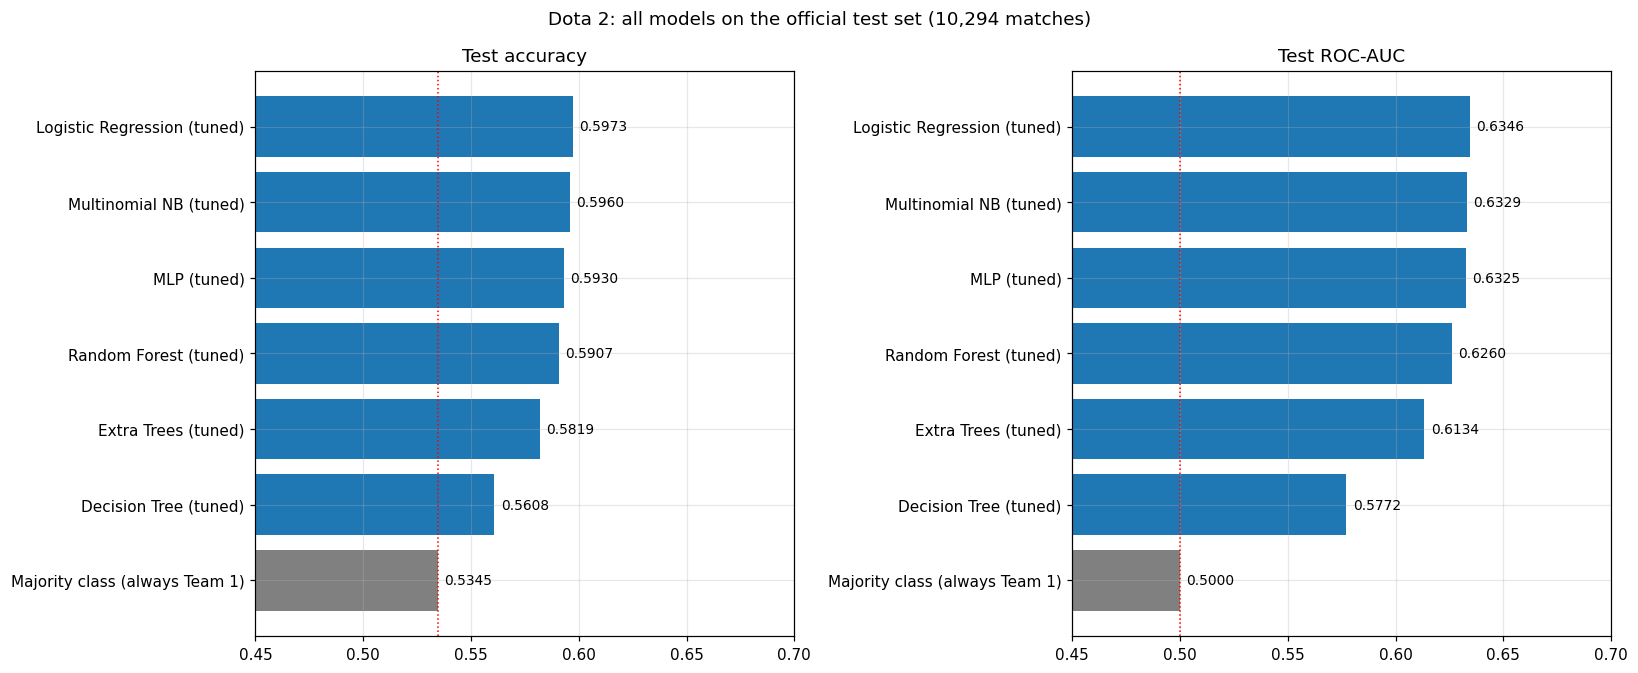

In [48]:
# Final comparison chart: test accuracy and ROC-AUC for every model, sorted.
chart = test_tbl[["model", "accuracy", "ROC_AUC"]].sort_values("ROC_AUC")
fig, axes = plt.subplots(1, 2, figsize=(15, 0.6 * len(chart) + 2))
for ax, (col, title, ref) in zip(axes, [("accuracy", "Test accuracy", y_test.mean()), ("ROC_AUC", "Test ROC-AUC", 0.5)]):
    ax.barh(chart.model, chart[col], color=["grey" if m.startswith("Majority") else "tab:blue" for m in chart.model])
    ax.axvline(ref, color="red", ls=":", lw=1)
    for i, v in enumerate(chart[col]):
        ax.text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=9)
    ax.set_xlim(0.45, max(0.7, chart[col].max() + 0.05)); ax.set_title(title)
plt.suptitle("Dota 2: all models on the official test set (10,294 matches)")
plt.tight_layout(); plt.savefig(FIG_DIR / "dota2_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 9.1 Generalisation with less training data
**Classifier 1** = trained on all training data, tested on the official test set (above). **Classifier 2 / 3:** 30 % / 60 % of the training matches are *moved* into the test set (new test = official test + moved matches), so the models learn from less data. Same fixed settings; we compare training and testing accuracy.

In [49]:
gen_rows = []
for frac, label in [(0.0, "Classifier 1 (all training data)"), (0.3, "Classifier 2 (30% moved to test)"), (0.6, "Classifier 3 (60% moved to test)")]:
    if frac == 0:
        Xa, ya, Xb, yb = X_train, y_train, X_test, y_test
    else:
        Xa, Xm, ya, ym = train_test_split(X_train, y_train, test_size=frac, stratify=y_train, random_state=SEED)
        Xb, yb = pd.concat([X_test, Xm]), pd.concat([y_test, ym])
    for name in models_no_dummy:
        m = clone(FINAL_CANDIDATES[name][0]).fit(Xa, ya); p = m.predict_proba(Xb)[:, 1]
        gen_rows.append(dict(setup=label, model=name, n_train=len(ya), n_test=len(yb),
                             train_acc=accuracy_score(ya, m.predict(Xa)), test_acc=accuracy_score(yb, p >= 0.5),
                             test_AUC=roc_auc_score(yb, p)))
gen_tbl = pd.DataFrame(gen_rows); gen_tbl["gap"] = gen_tbl.train_acc - gen_tbl.test_acc
save(gen_tbl, "dota2_generalisation_tree123")
table(gen_tbl, ["setup", "model", "n_train", "n_test", "train_acc", "test_acc", "gap", "test_AUC"], best_cols=["test_acc", "test_AUC"], lower_better=("gap",))

setup,model,n_train,n_test,train_acc,test_acc,gap,test_AUC
Classifier 1 (all training data),Decision Tree (tuned),92650,10294,0.5732,0.5608,0.0124,0.5772
Classifier 1 (all training data),Logistic Regression (tuned),92650,10294,0.6011,0.5973,0.0037,0.6346
Classifier 1 (all training data),Multinomial NB (tuned),92650,10294,0.6009,0.5960,0.0049,0.6329
Classifier 1 (all training data),Random Forest (tuned),92650,10294,0.6650,0.5907,0.0743,0.6260
Classifier 1 (all training data),Extra Trees (tuned),92650,10294,0.6402,0.5819,0.0584,0.6134
Classifier 1 (all training data),MLP (tuned),92650,10294,0.5994,0.5930,0.0064,0.6325
Classifier 2 (30% moved to test),Decision Tree (tuned),64855,38089,0.5726,0.5580,0.0146,0.5754
Classifier 2 (30% moved to test),Logistic Regression (tuned),64855,38089,0.5984,0.6037,-0.0053,0.6412
Classifier 2 (30% moved to test),Multinomial NB (tuned),64855,38089,0.5993,0.6001,-0.0008,0.6375
Classifier 2 (30% moved to test),Random Forest (tuned),64855,38089,0.6655,0.5899,0.0756,0.6254


In [50]:
# Does accuracy differ between game modes? (test set; wide intervals = too few matches to tell)
best_name = max(models_no_dummy, key=lambda n: roc_auc_score(y_test, test_proba[n]))
rows = []
for mode, label in [(2, "mode 2"), (8, "mode 8"), (9, "mode 9"), (1, "mode 1"), (0, "other modes")]:
    idx = (X_test["gamemode_grp"] == mode).to_numpy()
    if idx.sum() < 100:
        continue
    yy, pp = truth[idx], test_proba[best_name][idx]
    acc = accuracy_score(yy, pp >= 0.5)
    rows.append(dict(game_mode=label, matches=int(idx.sum()), majority_acc=max(yy.mean(), 1 - yy.mean()),
                     model_acc=acc, ci95=1.96 * np.sqrt(acc * (1 - acc) / idx.sum()), ROC_AUC=roc_auc_score(yy, pp)))
mode_tbl = pd.DataFrame(rows); save(mode_tbl, "dota2_per_mode_test")
print("Best model by test ROC-AUC:", best_name)
mode_tbl.round(4)

Best model by test ROC-AUC: Logistic Regression (tuned)


,game_mode,matches,majority_acc,model_acc,ci95,ROC_AUC
0,mode 2,7955,0.5332,0.5927,0.0108,0.6312
1,mode 8,897,0.5596,0.6221,0.0317,0.6630
2,mode 9,1167,0.5133,0.6084,0.0280,0.6453
3,mode 1,136,0.6029,0.5515,0.0836,0.4632
4,other modes,139,0.5540,0.6547,0.0790,0.6961


Logistic Regression had the highest test accuracy at 59.73%, beating the “always Team 1” baseline of 53.45% by 6.29 percentage points; all six trained models beat the baseline. Naive Bayes was almost identical at 59.60%, and their McNemar p-value of 0.60 gives no clear evidence of a difference. The Decision Tree performed worse at 56.08%, which suggests that combining many small hero signals appears more effective here than making one-feature-at-a-time splits.

Training, CV and test accuracy were close for Logistic Regression and Naive Bayes, while Random Forest and Extra Trees had larger gaps. With less training data, the simpler models remained fairly stable, while the forests generally weakened; however, the test set also changed, so this is not a perfectly controlled comparison. The models identified Team 1 wins more successfully than Team 2 wins—for example, Logistic Regression had 66.76% sensitivity and 51.67% specificity. ROC-AUC is a useful main comparison metric because it assesses performance across prediction thresholds, alongside accuracy; Team 1 F1 alone is misleading here because the always-Team-1 baseline receives a high F1 despite never identifying a Team 2 win.

&nbsp;

## 10. Summary of results and limitations

In [51]:
print("Experiments run (10-fold CV rows):", len(CV_RESULTS))
print("Inputs used:", BEST_PREP, "| tuned tree:", DT_BEST, "| LR C:", LR_C, "| Naive Bayes:", best_nb_name, "alpha", NB_ALPHA)
print("Random Forest:", RF_BEST, "| Extra Trees:", ET_BEST, "| MLP:", MLP_BEST)
for r in test_rows:
    print(f"  {r['model']:<32s} test accuracy {r['accuracy']:.4f} | F1 {r['F1']:.4f} | ROC-AUC {r['ROC_AUC']:.4f}")
pd.DataFrame(CV_RESULTS).to_csv(TABLE_DIR / "dota2_all_cv_experiments.csv", index=False)
print("All tables saved in", TABLE_DIR.resolve(), "| all figures in", FIG_DIR.resolve())

Experiments run (10-fold CV rows): 101
Inputs used: {'hero_repr': 'signed', 'use_cluster': False} | tuned tree: {'min_samples_split': 2, 'min_samples_leaf': 300, 'max_depth': None, 'criterion': 'gini'} | LR C: 1.0 | Naive Bayes: Multinomial NB alpha 10
Random Forest: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'log2'} | Extra Trees: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 10} | MLP: {'hidden_layer_sizes': (64, 32), 'activation': 'tanh', 'learning_rate_init': 0.001, 'early_stopping': True, 'n_iter_no_change': 10, 'max_iter': 150}
  Majority class (always Team 1)   test accuracy 0.5345 | F1 0.6966 | ROC-AUC 0.5000
  Decision Tree (tuned)            test accuracy 0.5608 | F1 0.6096 | ROC-AUC 0.5772
  Logistic Regression (tuned)      test accuracy 0.5973 | F1 0.6393 | ROC-AUC 0.6346
  Multinomial NB (tuned)           test accuracy 0.5960 | F1 0.6404 | ROC-AUC 0.6329
  Random Forest (tuned)            test accuracy 0.5907 | F1 0.6601 |

CONCLUSION: Hero picks and match settings can predict winners better than the majority baseline, but the best accuracy of about 60% shows that prediction remains difficult. Every trained model beats the baseline, while adding server region provides no meaningful improvement. Logistic Regression and Naive Bayes match or outperform the more complex models, although this does not prove that hero interactions are unimportant. Smaller feature sets retain some predictive value but generally perform worse than the full set. These findings are limited to one short snapshot of an older game version and exclude important information such as player skill and in-game decisions.

&nbsp;